# Experiment 3 — Language variation in speaker representations

Frozen ECAPA-TDNN and WavLM Large are compared on English, Chinese, and mixed-language ASCEND utterances using speaker verification.


## Environment

Install the speech-model and analysis dependencies.


In [2]:
import sys
import subprocess

print("Python:", sys.version)
if not ((3, 11) <= sys.version_info[:2] <= (3, 13)):
    raise RuntimeError("This dependency set targets Python 3.11–3.13.")

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "torch==2.6.0", "torchaudio==2.6.0",
    "--index-url", "https://download.pytorch.org/whl/cu124",
])

numpy_pin = "numpy==2.2.3" if sys.version_info >= (3, 13) else "numpy==1.26.4"
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--upgrade",
    "--only-binary=numpy,pandas,pyarrow,scipy,scikit-learn,matplotlib,sentencepiece,tokenizers",
    "torch==2.6.0", "torchaudio==2.6.0",
    "transformers==4.49.0", "speechbrain==1.0.3",
    "huggingface-hub==0.29.3", "tokenizers==0.21.4",
    numpy_pin, "pandas==2.2.3", "pyarrow==19.0.1",
    "scikit-learn==1.6.1", "scipy==1.15.2", "matplotlib==3.10.1",
    "soundfile==0.13.1", "tqdm==4.67.1", "psutil==7.0.0",
    "sentencepiece==0.2.1",
])

subprocess.check_call([
    sys.executable, "-m", "pip", "uninstall", "-y", "torchvision",
])

subprocess.check_call([sys.executable, "-c", """
import torch, torchaudio, numpy, pandas, pyarrow, scipy, sklearn, soundfile
from transformers import WavLMModel, Wav2Vec2FeatureExtractor
from speechbrain.inference.classifiers import EncoderClassifier
print('Import check passed.')
print('torch:', torch.__version__, 'torchaudio:', torchaudio.__version__)
print('numpy:', numpy.__version__, 'CUDA available:', torch.cuda.is_available())
"""])
print("Setup complete. Use Runtime > Restart session, then run from the configuration cell onward.")
print("Keep this replacement setup cell; do not rerun the old dependency pins.")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Setup complete. Use Runtime > Restart session, then run from the configuration cell onward.
Keep this replacement setup cell; do not rerun the old dependency pins.


## Configuration

Paths, preprocessing, model choices, trial sampling, and evaluation settings.


In [20]:
from pathlib import Path
import os, io, json, hashlib, random, warnings, gc, itertools, platform
from collections import Counter
from contextlib import nullcontext
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import torch, torchaudio
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve, roc_auc_score
import psutil
from IPython.display import display, Markdown

CFG = dict(
    seed=42, smoke_test=False, root='/content/drive/MyDrive/ASCEND',
    sample_rate=16000, min_duration=1.5, silence_rms=1e-5,
    chunk_seconds=12.0, batch_size=2, wavlm_amp=True,
    min_per_language=3, utterances_per_speaker_language=30,
    pairs_per_speaker_condition=30, bootstrap_replicates=200,
    smoke_speakers=8, smoke_utterances_per_language=4,
    cache_processed_audio=True, code_version='experiment3-v1.0',
    wavlm_model='microsoft/wavlm-large', ecapa_model='speechbrain/spkrec-ecapa-voxceleb',
    wavlm_revision='main', ecapa_revision='main',
)
assert CFG['min_duration'] > 0 and CFG['chunk_seconds'] >= CFG['min_duration']
assert CFG['min_per_language'] >= 2
assert CFG['utterances_per_speaker_language'] >= CFG['min_per_language']
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE == 'cuda', 'Select Runtime > Change runtime type > GPU, then rerun.'
print(torch.__version__, torchaudio.__version__, torch.cuda.get_device_name(0))
def digest(x):
    return hashlib.sha256(json.dumps(x, sort_keys=True, default=str).encode()).hexdigest()
def atomic_json(path, value):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(value, indent=2, default=str)); os.replace(tmp, path)
def atomic_npz(path, **arrays):
    path = Path(path); tmp = path.with_name(path.name+'.tmp')
    with tmp.open('wb') as f: np.savez_compressed(f, **arrays)
    os.replace(tmp, path)
def memory():
    print(f'RAM {psutil.Process().memory_info().rss/2**30:.2f} GiB; '
          f'GPU allocated {torch.cuda.memory_allocated()/2**30:.2f} GiB; '
          f'peak {torch.cuda.max_memory_allocated()/2**30:.2f} GiB')
NOTES=[]
def note(s):
    NOTES.append(s); warnings.warn(s)


2.6.0+cu124 2.6.0+cu124 NVIDIA A100-SXM4-80GB


## Load Google Drive

Locate ASCEND data and the experiment output directory.


In [21]:
from google.colab import drive
drive.mount('/content/drive')
ROOT=Path(CFG['root'])
OUT=ROOT/'experiment3_results'
if CFG['smoke_test']: OUT=OUT/'smoke'
for sub in ['', 'figures', 'embeddings/ecapa', 'embeddings/wavlm', 'cache']:
    (OUT/sub).mkdir(parents=True, exist_ok=True)
FILES=[ROOT/'main'/f for f in [
    'train-00000-of-00003.parquet','train-00001-of-00003.parquet',
    'train-00002-of-00003.parquet','validation-00000-of-00001.parquet',
    'test-00000-of-00001.parquet']]
assert all(p.is_file() for p in FILES), f'Missing files: {[str(p) for p in FILES if not p.is_file()]}'
assert (ROOT/'README.md').is_file(), 'The local ASCEND README.md is required for inspection.'
readme=(ROOT/'README.md').read_text(errors='replace')
display(Markdown(readme))
(OUT/'dataset_README_snapshot.md').write_text(readme)
atomic_json(OUT/'experiment_config.json', CFG)
if CFG['smoke_test']: note('SMOKE TEST: subsampled data; every metric is diagnostic only.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
annotations_creators:
- expert-generated
language_creators:
- crowdsourced
language:
- en
- zh
license:
- cc-by-sa-4.0
multilinguality:
- multilingual
size_categories:
- 10K<n<100K
source_datasets:
- original
task_categories:
- automatic-speech-recognition
task_ids: []
pretty_name: 'ASCEND: A Spontaneous Chinese-English Dataset for Code-switching in
  Multi-turn Conversation'
tags:
- speech-recognition
- code-switching
dataset_info:
  config_name: main
  features:
  - name: id
    dtype: string
  - name: path
    dtype: string
  - name: audio
    dtype:
      audio:
        sampling_rate: 16000
  - name: transcription
    dtype: string
  - name: duration
    dtype: float32
  - name: language
    dtype: string
  - name: original_speaker_id
    dtype: int64
  - name: session_id
    dtype: int64
  - name: topic
    dtype: string
  splits:
  - name: train
    num_bytes: 1014573740.14
    num_examples: 9869
  - name: test
    num_bytes: 106171230.135
    num_examples: 1315
  - name: validation
    num_bytes: 106772517.43
    num_examples: 1130
  download_size: 1223536062
  dataset_size: 1227517487.7050002
configs:
- config_name: main
  data_files:
  - split: train
    path: main/train-*
  - split: test
    path: main/test-*
  - split: validation
    path: main/validation-*
  default: true
---

# Dataset Card for ASCEND

## Table of Contents
- [Dataset Description](#dataset-description)
  - [Dataset Summary](#dataset-summary)
  - [Supported Tasks](#supported-tasks-and-leaderboards)
  - [Languages](#languages)
- [Usage](#usage)
- [Dataset Structure](#dataset-structure)
  - [Data Splits](#data-instances)
- [Additional Information](#additional-information)
  - [Licensing Information](#licensing-information)
  - [Citation Information](#citation-information)

## Dataset Description

- **Homepage:** [Needs More Information]
- **Repository:** [Needs More Information]
- **Paper:** https://arxiv.org/abs/2112.06223
- **Leaderboard:** [Needs More Information]
- **Point of Contact:** [Needs More Information]

### Dataset Summary

ASCEND (A Spontaneous Chinese-English Dataset) introduces a high-quality resource of spontaneous multi-turn conversational dialogue Chinese-English code-switching corpus collected in Hong Kong. ASCEND consists of 10.62 hours of spontaneous speech with a total of ~12.3K utterances. The corpus is split into 3 sets: training, validation, and test with a ratio of 8:1:1 while maintaining a balanced gender proportion on each set.

### Supported Tasks and Leaderboards

Code-switching

### Languages

Chinese and English

## Usage

To obtain the full dataset (complete with train, validation, and test set), simply run this:

```
import datasets
dataset = datasets.load_dataset("CAiRE/ASCEND")
```

## Dataset Structure

A typical data point comprises the path to the audio file, the loaded audio array, and its transcription. Additional fields include datapoint id, duration, language, speaker id, session id, and topic.

```
{
	'id': '00644',
	'path': '.cache/huggingface/datasets/downloads/extracted/f0b33b5266cd9452ee310eef3577cf7adb7f29aa54dbff74b9a8ee406a55d614/waves/ses2_spk3_L13101_189.900_5.490.wav',
	'audio': {
		'path': '.cache/huggingface/datasets/downloads/extracted/f0b33b5266cd9452ee310eef3577cf7adb7f29aa54dbff74b9a8ee406a55d614/waves/ses2_spk3_L13101_189.900_5.490.wav',
		'array': array([-6.1035156e-05, -1.8310547e-04, 3.0517578e-05, ...,
			0.0000000e+00, -3.0517578e-05, 0.0000000e+00
		], dtype = float32),
		'sampling_rate': 16000
	},
	'transcription': '因为你不可能邀你的female friends去说走我们去play basketball',
	'duration': 5.489999771118164,
	'language': 'mixed',
	'original_speaker_id': 3,
	'session_id': 2,
	'topic': 'sports'
}
```

### Data Splits

Number of utterances: 9,869 train, 1,130 validation, and 1,315 test.

## Additional Information

For comprehensive explanations, please check [our paper](https://arxiv.org/pdf/2112.06223.pdf).

### Licensing Information

Creative Common Attribution Share-Alike 4.0 International (CC-BY-SA 4.0)

### Citation Information

If you use our dataset, please cite us:

```
@inproceedings{lovenia2022ascend,
  title={ASCEND: A Spontaneous Chinese-English Dataset for Code-switching in Multi-turn Conversation},
  author={Lovenia, Holy and Cahyawijaya, Samuel and Winata, Genta Indra and Xu, Peng and Yan, Xu and Liu, Zihan and Frieske, Rita and Yu, Tiezheng and Dai, Wenliang and Barezi, Elham J and others},
  booktitle={Proceedings of the 13th Language Resources and Evaluation Conference (LREC)},
  year={2022}
 ```

## Read ASCEND recordings

Inspect Parquet schemas and assemble recording metadata.


In [22]:
def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024), b''): h.update(b)
    return h.hexdigest()
SOURCE_HASHES={p.name:file_sha(p) for p in tqdm(FILES, desc='Fingerprint source files')}
DATA_KEY=digest({'sources':SOURCE_HASHES,'code':CFG['code_version']})
meta_path=OUT/'cache'/f'metadata_{DATA_KEY}.parquet'
SCHEMAS={}
for p in FILES:
    pf=pq.ParquetFile(p); names=pf.schema_arrow.names
    SCHEMAS[p.name]=str(pf.schema_arrow)
    print('\n',p.name, 'rows=',pf.metadata.num_rows, '\n', pf.schema_arrow)
    assert {'audio','original_speaker_id','language'} <= set(names), f'Required fields missing: {p}'
    missing=set(['duration','session_id','transcription','id'])-set(names)
    if missing: note(f'{p.name}: missing optional fields {sorted(missing)}')
    sample=next(pf.iter_batches(batch_size=2)).to_pylist()
    for r in sample:
        a=r.get('audio'); b=a.get('bytes') if isinstance(a,dict) else a
        print({k:r.get(k) for k in ['original_speaker_id','language','duration','session_id','id']},
              'audio_type=',type(a).__name__, 'audio_keys=',list(a) if isinstance(a,dict) else None,
              'embedded_bytes=',len(b) if isinstance(b,(bytes,bytearray)) else None)
atomic_json(OUT/'schemas.json',SCHEMAS)
if meta_path.exists():
    meta=pd.read_parquet(meta_path)
else:
    records=[]
    for p in tqdm(FILES,desc='Index embedded records'):
        pf=pq.ParquetFile(p)
        for rg in range(pf.num_row_groups):
            table=pf.read_row_group(rg)
            for ri,r in enumerate(table.to_pylist()):
                a=r['audio']; b=a.get('bytes') if isinstance(a,dict) else a
                has_bytes=isinstance(b,(bytes,bytearray)) and len(b)>0
                audio_hash=hashlib.sha256(b).hexdigest() if has_bytes else ''
                source_identity=f'{p.name}:{rg}:{ri}'
                records.append(dict(
                    uid=hashlib.sha256(source_identity.encode()).hexdigest()[:24],
                    source_file=p.name, source_split=p.name.split('-')[0], row_group=rg, row_in_group=ri,
                    original_id=str(r.get('id','')), speaker=str(r['original_speaker_id']).strip()
                        if r['original_speaker_id'] is not None else '',
                    language=str(r['language']).strip().lower(),
                    duration_metadata=pd.to_numeric(r.get('duration'),errors='coerce'),
                    session=str(r['session_id']) if r.get('session_id') is not None else '',
                    has_embedded_bytes=has_bytes, audio_hash=audio_hash))
            del table
    meta=pd.DataFrame(records)
    meta.to_parquet(meta_path,index=False)
assert meta.uid.is_unique
print('Observed language values:', meta.language.value_counts(dropna=False).to_dict())
unknown=set(meta.language)-{'en','zh','mixed'}
if unknown: note(f'Unexpected language labels are audited but excluded: {sorted(unknown)}')
meta['index_reason']='candidate'
meta.loc[~meta.has_embedded_bytes,'index_reason']='missing_embedded_bytes'
meta.loc[meta.speaker.eq(''),'index_reason']='missing_speaker'
meta.loc[~meta.language.isin(['en','zh','mixed']),'index_reason']='unknown_language'
valid_hash=meta[meta.audio_hash.ne('')]
conflicts=valid_hash.groupby('audio_hash').agg(speakers=('speaker','nunique'),languages=('language','nunique'))
bad_hash=set(conflicts.index[(conflicts.speakers>1)|(conflicts.languages>1)])
meta.loc[meta.audio_hash.isin(bad_hash),'index_reason']='conflicting_duplicate'
remaining=meta.index[meta.index_reason.eq('candidate')]
dup=meta.loc[remaining,'audio_hash'].duplicated()
meta.loc[remaining[dup],'index_reason']='duplicate_audio'
meta.to_parquet(OUT/'metadata_index.parquet',index=False)
print('Speakers overlapping official splits:',
      int((meta.groupby('speaker').source_split.nunique()>1).sum()))
print('All original rows:',len(meta),'speakers:',meta.loc[meta.speaker.ne(''),'speaker'].nunique())
display(meta.groupby('language').agg(recordings=('uid','size'),
    metadata_seconds=('duration_metadata',lambda x:x.sum(min_count=1))))


Fingerprint source files:   0%|          | 0/5 [00:00<?, ?it/s]


 train-00000-of-00003.parquet rows= 3290 
 id: string
path: string
audio: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
transcription: string
duration: float
language: string
original_speaker_id: int64
session_id: int64
topic: string
-- schema metadata --
huggingface: '{"info": {"features": {"id": {"dtype": "string", "_type": "' + 430
{'original_speaker_id': 1, 'language': 'mixed', 'duration': 1.559999942779541, 'session_id': 1, 'id': '00000'} audio_type= dict audio_keys= ['bytes', 'path'] embedded_bytes= 49964
{'original_speaker_id': 1, 'language': 'mixed', 'duration': 4.159999847412109, 'session_id': 1, 'id': '00001'} audio_type= dict audio_keys= ['bytes', 'path'] embedded_bytes= 133164

 train-00001-of-00003.parquet rows= 3290 
 id: string
path: string
audio: struct<bytes: binary, path: string>
  child 0, bytes: binary
  child 1, path: string
transcription: string
duration: float
language: string
original_speaker_id: int64
session_id: int64
to

Index embedded records:   0%|          | 0/5 [00:00<?, ?it/s]

Observed language values: {'zh': 6139, 'mixed': 3325, 'en': 2850}
Speakers overlapping official splits: 0
All original rows: 12314 speakers: 23


,recordings,metadata_seconds
language,,
en,2850,7187.686002
mixed,3325,15514.663999
zh,6139,15513.624000


## Dataset overview

Summarize available speakers, language labels, and recording counts.


In [23]:
def language_counts(frame):
    return pd.crosstab(frame.speaker,frame.language).reindex(columns=['en','zh','mixed'],fill_value=0)
raw_counts=language_counts(meta)
raw_counts.to_csv(OUT/'speaker_language_counts_raw.csv')
display(raw_counts)
candidates=meta[meta.index_reason.eq('candidate')].copy()
provisional=language_counts(candidates)
print('Provisional bilingual speakers:',int(((provisional.en>=CFG['min_per_language']) &
    (provisional.zh>=CFG['min_per_language'])).sum()))
if CFG['smoke_test']:
    bilingual=sorted(provisional.index[(provisional.en>=CFG['min_per_language']) &
                                    (provisional.zh>=CFG['min_per_language'])])
    rng=np.random.default_rng(CFG['seed'])
    keep=rng.permutation(bilingual)[:CFG['smoke_speakers']]
    candidates=(candidates[candidates.speaker.isin(keep)].sort_values('uid')
        .groupby(['speaker','language'],group_keys=False)
        .head(CFG['smoke_utterances_per_language']).copy())
    note(f'Smoke decode scope: {len(candidates)} utterances from {len(keep)} provisional bilingual speakers.')


language,en,zh,mixed
speaker,,,
1,199,356,288
10,75,371,268
11,26,271,143
12,146,374,126
13,198,106,138
14,226,184,89
15,114,211,137
16,109,369,174
17,233,478,150


Provisional bilingual speakers: 23


## Preprocess audio

Decode, resample, validate, and cache usable 16 kHz utterances.


In [24]:
PREP={k:CFG[k] for k in ['code_version','sample_rate','min_duration','silence_rms']}
PREP_KEY=digest(PREP)
AUDIO_DIR=OUT/'cache'/'audio'/PREP_KEY
AUDIO_DIR.mkdir(parents=True,exist_ok=True)
AUDIT_PATH=OUT/'cache'/f'audio_audit_{digest([DATA_KEY,PREP_KEY,sorted(candidates.uid)])}.parquet'
def prepare_bytes(b):
    x,sr=sf.read(io.BytesIO(b),dtype='float32',always_2d=True)
    if x.size==0: raise ValueError('empty_audio')
    if not np.isfinite(x).all(): raise ValueError('nonfinite_audio')
    x=x.mean(axis=1)
    original_sr=int(sr)
    if sr != CFG['sample_rate']:
        x=torchaudio.functional.resample(torch.from_numpy(x),sr,CFG['sample_rate']).numpy()
    x=x.astype('float32'); x=x-x.mean()
    duration=len(x)/CFG['sample_rate']; rms=float(np.sqrt(np.mean(x*x,dtype=np.float64)))
    if duration<CFG['min_duration']: raise ValueError('too_short')
    if rms<CFG['silence_rms']: raise ValueError('silent')
    x=x/max(1.0,float(np.abs(x).max()))
    return x,dict(duration=duration,rms=rms,original_sr=original_sr,n_samples=len(x))
def audio_path(row): return AUDIO_DIR/(str(row['audio_hash'])+'.npz')
def get_bytes(record):
    table=pq.ParquetFile(ROOT/'main'/record['source_file']).read_row_group(int(record['row_group']),columns=['audio'])
    a=table.column('audio')[int(record['row_in_group'])].as_py()
    return a.get('bytes') if isinstance(a,dict) else a
def iter_audio_rows(frame):
    for (name,rg),group in frame.groupby(['source_file','row_group'],sort=True):
        need=group.copy()
        uncached=need[[not audio_path(r).exists() for r in need.to_dict('records')]]
        table=None
        if len(uncached):
            table=pq.ParquetFile(ROOT/'main'/name).read_row_group(int(rg),columns=['audio'])
        for r in need.to_dict('records'):
            path=audio_path(r)
            if path.exists():
                with np.load(path,allow_pickle=False) as z:
                    x=z['audio'].copy(); r['decoded_original_sr']=int(z['original_sr'])
                yield r,x,None
            else:
                try:
                    a=table.column('audio')[int(r['row_in_group'])].as_py()
                    b=a.get('bytes') if isinstance(a,dict) else a
                    x,decoded=prepare_bytes(b)
                    r['decoded_original_sr']=decoded['original_sr']
                    if CFG['cache_processed_audio']: atomic_npz(path,audio=x,original_sr=np.array(decoded['original_sr']))
                    yield r,x,None
                except Exception as e:
                    yield r,None,f'{type(e).__name__}: {str(e)[:180]}'
        del table

audit_records=pd.read_parquet(AUDIT_PATH).to_dict('records') if AUDIT_PATH.exists() else []
done={r['uid'] for r in audit_records}
pending=candidates[~candidates.uid.isin(done)]
for (_, _), group in tqdm(pending.groupby(['source_file','row_group']),
                          total=pending.groupby(['source_file','row_group']).ngroups,desc='Audio audit'):
    for r,x,error in iter_audio_rows(group):
        info=dict(uid=r['uid'],usable=error is None,audio_error=error or '',duration=np.nan,
                  rms=np.nan,n_samples=0,original_sr=r.get('decoded_original_sr',np.nan))
        if x is not None:
            info.update(duration=len(x)/CFG['sample_rate'],n_samples=len(x),
                        rms=float(np.sqrt(np.mean(x*x,dtype=np.float64))))
        audit_records.append(info)
    tmp=AUDIT_PATH.with_suffix('.tmp.parquet')
    pd.DataFrame(audit_records).to_parquet(tmp,index=False); os.replace(tmp,AUDIT_PATH)
audio_audit=pd.DataFrame(audit_records,columns=['uid','usable','audio_error','duration','rms','n_samples','original_sr'])
audit=meta.merge(audio_audit,on='uid',how='left',validate='one_to_one')
audit['status']=audit.index_reason
mask=audit.index_reason.eq('candidate')
audit.loc[mask & audit.usable.eq(True),'status']='usable'
audit.loc[mask & audit.usable.eq(False),'status']='audio_rejected'
audit.loc[mask & audit.usable.isna(),'status']='not_processed_smoke_scope'
audit.to_csv(OUT/'dataset_audit.csv',index=False)
usable=audit[audit.status.eq('usable')].copy()
usable_counts=language_counts(usable)
usable_counts.to_csv(OUT/'speaker_language_counts_usable.csv')
filter_summary=audit.groupby(['speaker','language','status']).size().rename('utterances').reset_index()
filter_summary.to_csv(OUT/'filtering_by_speaker_language.csv',index=False)
display(audit.groupby(['language','status']).agg(utterances=('uid','size'),decoded_seconds=('duration','sum')))
display(usable.groupby('language').duration.describe())
print('Audio rejection reasons:',audit.audio_error.value_counts().head(15).to_dict())
eligible=sorted(usable_counts.index[(usable_counts.en>=CFG['min_per_language']) &
                                   (usable_counts.zh>=CFG['min_per_language'])])
FEASIBLE=len(eligible)>=4
if not FEASIBLE: note(f'INFEASIBLE: only {len(eligible)} usable bilingual speakers; need at least 4 for disjoint dev/test with impostors.')
if len(eligible)<10: note(f'Only {len(eligible)} eligible bilingual speakers: results, if computable, are highly exploratory.')
if FEASIBLE:
    inference_rows=usable[usable.speaker.isin(eligible) & usable.language.isin(['en','zh','mixed'])].copy()
    # Balanced utterance cap for tractable inference and per-speaker trial generation.
    inference_rows['selection_key']=inference_rows.uid.map(lambda u:digest([CFG['seed'],u]))
    inference_rows=(inference_rows.sort_values('selection_key').groupby(['speaker','language'],group_keys=False)
        .head(CFG['utterances_per_speaker_language']).drop(columns='selection_key'))
else:
    inference_rows=usable.iloc[:0].copy()
inference_rows.to_csv(OUT/'inference_manifest.csv',index=False)
atomic_json(OUT/'feasibility.json',dict(feasible=FEASIBLE,eligible_speakers=eligible,
    raw_rows=len(meta),usable_rows=len(usable),smoke_test=CFG['smoke_test']))


Audio audit:   0%|          | 0/125 [00:00<?, ?it/s]

utterances  decoded_seconds
language status                                     
en       audio_rejected         995         0.000000
         usable                1855      6274.655313
mixed    audio_rejected         182         0.000000
         usable                3143     15294.942375
zh       audio_rejected        2384         0.000000
         usable                3755     13449.330813

,count,mean,std,min,25%,50%,75%,max
language,,,,,,,,
en,1855.0,3.382564,1.712147,1.5,2.140000,2.900,4.100000,13.26
mixed,3143.0,4.866351,2.561138,1.5,2.890031,4.281,6.260000,15.00
zh,3755.0,3.581713,1.957683,1.5,2.150187,3.010,4.445125,14.02


Audio rejection reasons: {'': 8753, 'ValueError: too_short': 3561}


## Load frozen models

Initialize pretrained ECAPA-TDNN and WavLM Large.


In [25]:
from huggingface_hub import HfApi, snapshot_download
from transformers import WavLMModel, Wav2Vec2FeatureExtractor
from speechbrain.inference.classifiers import EncoderClassifier
import importlib.metadata as im
PACKAGES={p:im.version(p) for p in ['torch','torchaudio','transformers','speechbrain',
    'huggingface-hub','numpy','pandas','pyarrow','scikit-learn','scipy','soundfile']}
atomic_json(OUT/'environment.json',dict(python=platform.python_version(),packages=PACKAGES,
    gpu=torch.cuda.get_device_name(0),cuda=torch.version.cuda))
(OUT/'requirements_runtime.txt').write_text(chr(10).join(sorted(
    f'{d.metadata["Name"]}=={d.version}' for d in im.distributions() if d.metadata.get('Name')))+chr(10))
MODEL_INFO={}
if FEASIBLE:
    requested={k:dict(repo=CFG[f'{k}_model'],revision=CFG[f'{k}_revision']) for k in ['ecapa','wavlm']}
    lock=OUT/'cache'/f'model_lock_{digest(requested)}.json'
    if lock.exists(): MODEL_INFO=json.loads(lock.read_text())
    else:
        MODEL_INFO={k:dict(**v,sha=HfApi().model_info(v['repo'],revision=v['revision']).sha)
                    for k,v in requested.items()}
        atomic_json(lock,MODEL_INFO)
    print(MODEL_INFO)
atomic_json(OUT/'model_versions.json',MODEL_INFO)
def load_model(kind):
    v=MODEL_INFO[kind]
    if kind=='ecapa':
        snap=snapshot_download(v['repo'],revision=v['sha'])
        model=EncoderClassifier.from_hparams(source=snap,
            savedir=str(Path('/content/experiment3_models')/v['sha']),
            hparams_file='hyperparams.yaml',overrides={'pretrained_path':snap},
            run_opts={'device':DEVICE})
        model.eval()
        for p in model.parameters(): p.requires_grad_(False)
        return model,None
    model=WavLMModel.from_pretrained(v['repo'],revision=v['sha']).to(DEVICE).eval()
    for p in model.parameters(): p.requires_grad_(False)
    assert model.config.num_hidden_layers==24
    extractor=Wav2Vec2FeatureExtractor.from_pretrained(v['repo'],revision=v['sha'])
    return model,extractor


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


{'ecapa': {'repo': 'speechbrain/spkrec-ecapa-voxceleb', 'revision': 'main', 'sha': '0f99f2d0ebe89ac095bcc5903c4dd8f72b367286'}, 'wavlm': {'repo': 'microsoft/wavlm-large', 'revision': 'main', 'sha': 'c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c'}}


## Extract speaker representations

Generate normalized embeddings for ECAPA and all 24 WavLM layers.


In [26]:
def chunks_for(x):
    size=round(CFG['chunk_seconds']*CFG['sample_rate'])
    chunks=[x[i:i+size] for i in range(0,len(x),size)]
    # Avoid a tiny tail that cannot pass the convolutional front end.
    if len(chunks)>1 and len(chunks[-1])<round(CFG['min_duration']*CFG['sample_rate']):
        chunks[-2]=np.concatenate([chunks[-2],chunks[-1]]); chunks.pop()
    return chunks

def infer_chunk_batch(kind,model,extractor,arrays):
    lengths=torch.tensor([len(x) for x in arrays],device=DEVICE)
    if kind=='ecapa':
        padded=torch.zeros(len(arrays),int(lengths.max()),device=DEVICE)
        for j,x in enumerate(arrays): padded[j,:len(x)]=torch.from_numpy(x).to(DEVICE)
        with torch.inference_mode():
            z=model.encode_batch(padded,lengths/lengths.max()).squeeze(1).float()
        return z.cpu().numpy()[:,None,:],lengths.cpu().numpy().astype('float64')
    batch=extractor(arrays,sampling_rate=CFG['sample_rate'],padding=True,
                    return_attention_mask=True,return_tensors='pt')
    inputs={k:v.to(DEVICE) for k,v in batch.items()}
    context=torch.autocast('cuda',dtype=torch.float16) if CFG['wavlm_amp'] else nullcontext()
    with torch.inference_mode(), context:
        output=model(**inputs,output_hidden_states=True,return_dict=True)
        states=output.hidden_states
        assert len(states)==25
        frame_mask=model._get_feature_vector_attention_mask(states[1].shape[1],inputs['attention_mask'])
        assert frame_mask.any(dim=1).all()
        weights=frame_mask.sum(dim=1).float()
        pooled=torch.stack([(s.float()*frame_mask.unsqueeze(-1)).sum(1)/weights[:,None]
                            for s in states[1:]],dim=1)
    result=pooled.cpu().numpy(); frame_weights=weights.cpu().numpy()
    del output,states,pooled,inputs,batch
    return result,frame_weights

def safe_infer(kind,model,extractor,arrays):
    try: return infer_chunk_batch(kind,model,extractor,arrays)
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        if len(arrays)==1: raise RuntimeError('A single chunk exceeds GPU memory; lower chunk_seconds.')
        mid=len(arrays)//2
        a,wa=safe_infer(kind,model,extractor,arrays[:mid])
        b,wb=safe_infer(kind,model,extractor,arrays[mid:])
        return np.concatenate([a,b]),np.concatenate([wa,wb])

CACHE_KEYS={}; CACHE_DIRS={}
for kind in ['ecapa','wavlm']:
    if not FEASIBLE: continue
    key=digest(dict(source=DATA_KEY,preprocessing=PREP,model=MODEL_INFO[kind],
        packages=PACKAGES,chunk_seconds=CFG['chunk_seconds'],batch_size=CFG['batch_size'],
        precision='fp16' if kind=='wavlm' and CFG['wavlm_amp'] else 'fp32',pooling='chunk_weighted_v1'))
    CACHE_KEYS[kind]=key
    folder=OUT/'embeddings'/kind/key; folder.mkdir(parents=True,exist_ok=True); CACHE_DIRS[kind]=folder
    atomic_json(folder/'cache_metadata.json',dict(cache_key=key,model=MODEL_INFO[kind],
        preprocessing=PREP,config=CFG,packages=PACKAGES,source_hashes=SOURCE_HASHES))
    def complete(row):
        path=folder/(row['uid']+'.npz')
        if not path.exists(): return False
        try:
            with np.load(path,allow_pickle=False) as z:
                e=z['embedding']
                return (str(z['cache_key'])==key and str(z['uid'])==row['uid'] and
                    str(z['speaker'])==row['speaker'] and str(z['language'])==row['language'] and
                    e.ndim==2 and e.shape[0]==(24 if kind=='wavlm' else 1) and
                    np.isfinite(e).all() and np.allclose(np.linalg.norm(e,axis=1),1,atol=2e-4))
        except Exception: return False
    remaining=inference_rows[[not complete(r) for r in inference_rows.to_dict('records')]]
    print(kind, 'remaining=',len(remaining),'cached=',len(inference_rows)-len(remaining))
    if not len(remaining): continue
    model,extractor=load_model(kind)
    assert not model.training and all(not p.requires_grad for p in model.parameters())
    for start in tqdm(range(0,len(remaining),CFG['batch_size']),desc=f'{kind} embeddings'):
        group=remaining.iloc[start:start+CFG['batch_size']]
        waveforms=[]
        for r,x,error in iter_audio_rows(group):
            assert error is None, f'Previously usable audio failed: {r["uid"]}: {error}'
            waveforms.append((r,x))
        chunk_list=[(r['uid'],x) for r,a in waveforms for x in chunks_for(a)]
        chunk_list.sort(key=lambda t:len(t[1]))
        sums={}; totals={}
        for i in range(0,len(chunk_list),CFG['batch_size']):
            part=chunk_list[i:i+CFG['batch_size']]
            z,w=safe_infer(kind,model,extractor,[x for _,x in part])
            assert np.isfinite(z).all(), 'Nonfinite embeddings: set wavlm_amp=False and rerun.'
            for (uid,_),embedding,weight in zip(part,z,w):
                sums[uid]=sums.get(uid,0)+embedding.astype('float64')*float(weight)
                totals[uid]=totals.get(uid,0)+float(weight)
        for r,_ in waveforms:
            e=(sums[r['uid']]/totals[r['uid']]).astype('float32')
            norms=np.linalg.norm(e,axis=-1,keepdims=True); assert (norms>1e-8).all()
            e=e/norms
            atomic_npz(folder/(r['uid']+'.npz'),embedding=e,uid=np.array(r['uid']),
                speaker=np.array(r['speaker']),language=np.array(r['language']),cache_key=np.array(key))
        del waveforms,chunk_list,sums
    del model,extractor; gc.collect(); torch.cuda.empty_cache(); memory()
atomic_json(OUT/'cache_keys.json',CACHE_KEYS)
IDS=inference_rows.uid.tolist(); UID_INDEX={u:i for i,u in enumerate(IDS)}
EMBEDDINGS={}
if FEASIBLE:
    for kind in ['ecapa','wavlm']:
        array=[]
        for uid in tqdm(IDS,desc=f'Load cached {kind}'):
            with np.load(CACHE_DIRS[kind]/(uid+'.npz'),allow_pickle=False) as z:
                assert str(z['cache_key'])==CACHE_KEYS[kind]; array.append(z['embedding'])
        EMBEDDINGS[kind]=np.stack(array)
        assert np.allclose(np.linalg.norm(EMBEDDINGS[kind],axis=-1),1,atol=2e-4)
        atomic_npz(OUT/'embeddings'/kind/'index.npz',uid=np.array(IDS),
            speaker=inference_rows.speaker.to_numpy(dtype=str),
            language=inference_rows.language.to_numpy(dtype=str),cache_key=np.array(CACHE_KEYS[kind]))


ecapa remaining= 2012 cached= 0


Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

.gitattributes:   0%|          | 0.00/858 [00:00<?, ?B/s]

hyperparams.yaml: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

example1.wav:   0%|          | 0.00/104k [00:00<?, ?B/s]

... (15 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:5962: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


RAM 3.60 GiB; GPU allocated 0.03 GiB; peak 1.78 GiB


Load cached ecapa:   0%|          | 0/2012 [00:00<?, ?it/s]

Load cached wavlm:   0%|          | 0/2012 [00:00<?, ?it/s]

## Speaker-disjoint splits

Assign bilingual speakers to development, test, and unused training-reserve sets.


In [27]:
partition_map={}
if FEASIBLE:
    shuffled=np.random.default_rng(CFG['seed']).permutation(eligible).tolist(); n=len(shuffled)
    if n>=20:
        ndev=max(4,round(.2*n)); ntest=max(4,round(.2*n)); ntrain=n-ndev-ntest
    else: ntrain=0; ndev=n//2; ntest=n-ndev
    partition_map.update({s:'train' for s in shuffled[:ntrain]})
    partition_map.update({s:'development' for s in shuffled[ntrain:ntrain+ndev]})
    partition_map.update({s:'test' for s in shuffled[ntrain+ndev:]})
    groups={p:{s for s,v in partition_map.items() if v==p} for p in ['train','development','test']}
    assert not any(groups[a]&groups[b] for a,b in itertools.combinations(groups,2))
    assert len(groups['development'])>=2 and len(groups['test'])>=2
    if min(len(groups['development']),len(groups['test']))<5:
        note('Fewer than five speakers in an evaluation partition; bootstrap intervals are unstable and population generalization is unsupported.')
inference_rows['partition']=inference_rows.speaker.map(partition_map)
pd.DataFrame([dict(speaker=s,partition=p) for s,p in sorted(partition_map.items())],
             columns=['speaker','partition']).to_csv(OUT/'speaker_partitions.csv',index=False)
atomic_json(OUT/'speaker_partition_mapping.json',partition_map)
print(Counter(partition_map.values()))


Counter({'train': 13, 'development': 5, 'test': 5})


## Verification trial construction

Create balanced genuine and impostor pairs by language condition.


In [28]:
PAIR_COLS=['pair_id','partition','condition','label','uid_a','uid_b','speaker_a','speaker_b',
           'language_a','language_b','duration_a','duration_b','session_a','session_b','same_session']
INFO=inference_rows.set_index('uid').to_dict('index')
def make_condition(frame,partition,la,lb):
    rng=np.random.default_rng(int(digest([CFG['seed'],partition,la,lb])[:16],16))
    counts=language_counts(frame)
    speakers=sorted(counts.index[(counts[la]>=2)&(counts[lb]>=2)])
    if len(speakers)<2: return []
    pools={}
    for s in speakers:
        for lang in set([la,lb]):
            pools[s,lang]=rng.permutation(sorted(frame.loc[(frame.speaker==s)&(frame.language==lang),'uid'])).tolist()
    capacity=min((len(pools[s,la])*(len(pools[s,la])-1)//2 if la==lb else
                  len(pools[s,la])*len(pools[s,lb])) for s in speakers)
    k=min(CFG['pairs_per_speaker_condition'],capacity)
    condition=f'{la}-{lb}'
    def pack(a,b,label):
        ra,rb=INFO[a],INFO[b]
        pairid=digest([partition,condition,*sorted([a,b])])[:24]
        sa,sb=ra['session'],rb['session']
        return dict(pair_id=pairid,partition=partition,condition=condition,label=label,
            uid_a=a,uid_b=b,speaker_a=ra['speaker'],speaker_b=rb['speaker'],
            language_a=ra['language'],language_b=rb['language'],
            duration_a=ra['duration'],duration_b=rb['duration'],session_a=sa,session_b=sb,
            same_session=(sa==sb) if sa and sb else None)
    rows=[]; seen=set()
    for s in speakers:
        aa,bb=pools[s,la],pools[s,lb]
        candidates=(list(itertools.combinations(aa,2)) if la==lb else list(itertools.product(aa,bb)))
        # Greedy degree balancing spreads each speaker's genuine trials across utterances.
        usage=Counter(); jitter=rng.random(len(candidates))
        for _ in range(k):
            idx=min(range(len(candidates)),key=lambda j:(usage[candidates[j][0]]+usage[candidates[j][1]],jitter[j]))
            a,b=candidates.pop(idx); jitter=np.delete(jitter,idx)
            usage.update([a,b]); rows.append(pack(a,b,1))
        others=[t for t in speakers if t!=s]; rng.shuffle(others)
        usage=Counter()
        for j in range(k):
            options=[]
            for offset in range(len(others)):
                t=others[(j+offset)%len(others)]
                for a in aa:
                    for b in pools[t,lb]:
                        token=tuple(sorted([a,b]))
                        if token not in seen:
                            options.append((offset,usage[a]+usage[b],rng.random(),a,b))
                if options: break
            assert options, 'Insufficient unique impostor trials; reduce pairs_per_speaker_condition.'
            _,_,_,a,b=min(options)
            seen.add(tuple(sorted([a,b]))); usage.update([a,b]); rows.append(pack(a,b,0))
    return rows

primary=[]; exploratory=[]
if FEASIBLE:
    for partition in ['development','test']:
        frame=inference_rows[inference_rows.partition.eq(partition)]
        for la,lb in [('en','en'),('zh','zh'),('en','zh')]:
            primary+=make_condition(frame,partition,la,lb)
        for la,lb in [('en','mixed'),('zh','mixed'),('mixed','mixed')]:
            rows=make_condition(frame,partition,la,lb)
            if not rows: note(f'Exploratory {partition} {la}-{lb}: insufficient speakers/utterances.')
            exploratory+=rows
pairs=pd.DataFrame(primary,columns=PAIR_COLS)
mixed_pairs=pd.DataFrame(exploratory,columns=PAIR_COLS)
for frame in [pairs,mixed_pairs]:
    if not len(frame): continue
    assert frame.pair_id.is_unique
    assert ((frame.speaker_a==frame.speaker_b)==frame.label.eq(1)).all()
    assert all(partition_map[s]==p for s,p in zip(frame.speaker_a,frame.partition))
    assert all(partition_map[s]==p for s,p in zip(frame.speaker_b,frame.partition))
    balance=frame.groupby(['partition','condition','label']).size().unstack(fill_value=0)
    assert (balance[0]==balance[1]).all()
    display(balance)
assert not len(pairs) or not pairs[['language_a','language_b']].isin(['mixed']).any().any()
pairs.to_csv(OUT/'verification_pairs.csv',index=False)
mixed_pairs.to_csv(OUT/'mixed_verification_pairs.csv',index=False)
confounds=[]
for scope,frame in [('primary',pairs),('mixed',mixed_pairs)]:
    if not len(frame): continue
    frame=frame.assign(mean_duration=(frame.duration_a+frame.duration_b)/2,
        abs_duration_gap=abs(frame.duration_a-frame.duration_b))
    t=frame.groupby(['partition','condition','label']).agg(n=('pair_id','size'),
        mean_duration=('mean_duration','mean'),mean_absolute_duration_gap=('abs_duration_gap','mean'),
        known_session_pairs=('same_session','count'),same_session_fraction=('same_session','mean')).reset_index()
    t['scope']=scope; confounds.append(t)
confound_table=pd.concat(confounds,ignore_index=True) if confounds else pd.DataFrame()
confound_table.to_csv(OUT/'trial_confounds.csv',index=False)
display(confound_table)

def duration_match(frame):
    chosen=[]; rng=np.random.default_rng(CFG['seed']+913)
    for partition,part in frame.groupby('partition'):
        part=part.copy()
        mean=(part.duration_a+part.duration_b)/2; gap=abs(part.duration_a-part.duration_b)
        part['stratum']=list(zip(np.digitize(mean,[2,3,5,8,12,20,40]),np.digitize(gap,[1,2,4,8,16])))
        required=set(itertools.product(['en-en','zh-zh','en-zh'],[0,1]))
        for _,g in part.groupby('stratum'):
            buckets={(c,int(y)):t for (c,y),t in g.groupby(['condition','label'])}
            if not required<=set(buckets): continue
            quota=min(len(buckets[k]) for k in required)
            for k in sorted(required): chosen.extend(rng.choice(buckets[k].pair_id,quota,replace=False))
    return frame[frame.pair_id.isin(chosen)].copy()
matched_pairs=duration_match(pairs) if len(pairs) else pairs.copy()
matched_pairs.to_csv(OUT/'duration_matched_pairs.csv',index=False)
if not len(matched_pairs): note('Duration-matched sensitivity analysis infeasible: no shared duration strata.')


label                    0    1
partition   condition          
development en-en      150  150
            en-zh      150  150
            zh-zh      150  150
test        en-en      150  150
            en-zh      150  150
            zh-zh      150  150

label                      0    1
partition   condition            
development en-mixed     150  150
            mixed-mixed  150  150
            zh-mixed     150  150
test        en-mixed     150  150
            mixed-mixed  150  150
            zh-mixed     150  150

,partition,condition,label,n,mean_duration,mean_absolute_duration_gap,known_session_pairs,same_session_fraction,scope
0,development,en-en,0,150,3.755558,2.294794,150,0.206667,primary
1,development,en-en,1,150,3.720670,2.160336,150,0.393333,primary
2,development,en-zh,0,150,3.749744,2.305250,150,0.233333,primary
3,development,en-zh,1,150,3.759531,2.308202,150,0.273333,primary
4,development,zh-zh,0,150,3.838553,2.233305,150,0.166667,primary
5,development,zh-zh,1,150,3.820191,2.078727,150,0.333333,primary
6,test,en-en,0,150,3.427259,1.904474,150,0.240000,primary
7,test,en-en,1,150,3.461132,1.867670,150,0.346667,primary
8,test,en-zh,0,150,3.491937,1.997175,150,0.293333,primary
9,test,en-zh,1,150,3.507617,2.069135,150,0.253333,primary


## Cosine similarity scores

Score each trial using the frozen representations.


In [29]:
MODEL_NAMES=['ECAPA']+[f'WavLM_L{i:02d}' for i in range(1,25)]
def get_vectors(name):
    return EMBEDDINGS['ecapa'][:,0,:] if name=='ECAPA' else EMBEDDINGS['wavlm'][:,int(name[-2:])-1,:]
def score_trials(frame):
    if not len(frame): return pd.DataFrame(columns=PAIR_COLS+['model','score'])
    a=frame.uid_a.map(UID_INDEX).to_numpy(); b=frame.uid_b.map(UID_INDEX).to_numpy()
    assert not pd.isna(a).any() and not pd.isna(b).any()
    tables=[]
    for name in MODEL_NAMES:
        z=get_vectors(name)
        s=np.einsum('ij,ij->i',z[a],z[b]).clip(-1,1)
        t=frame.copy(); t['model']=name; t['score']=s; tables.append(t)
    return pd.concat(tables,ignore_index=True)
scores=score_trials(pairs); mixed_scores=score_trials(mixed_pairs)
scores.to_parquet(OUT/'pair_scores.parquet',index=False)
mixed_scores.to_parquet(OUT/'mixed_pair_scores.parquet',index=False)
print('Scored primary trials:',len(scores))


Scored primary trials: 45000


## Verification metrics

Compute EER, ROC-AUC, and development-calibrated FAR/FRR.


In [30]:
def empirical_metrics(y,s,weights=None):
    y=np.asarray(y,dtype=int); s=np.asarray(s,dtype=float)
    w=np.ones(len(y)) if weights is None else np.asarray(weights,dtype=float)
    if (w[y==0].sum()<=0 or w[y==1].sum()<=0): return dict(eer=np.nan,roc_auc=np.nan)
    fpr,tpr,_=roc_curve(y,s,sample_weight=w,drop_intermediate=False)
    d=fpr-(1-tpr)
    k=int(np.flatnonzero(d>=0)[0])
    if k==0: eer=float(fpr[0])
    else:
        alpha=-d[k-1]/(d[k]-d[k-1])
        eer=float(fpr[k-1]+alpha*(fpr[k]-fpr[k-1]))
    return dict(eer=eer,roc_auc=float(roc_auc_score(y,s,sample_weight=w)))

def far_threshold(impostors,target):
    x=np.sort(np.asarray(impostors,dtype=np.float64))[::-1]
    assert len(x)>0
    allowed=int(np.floor(target*len(x)))
    # Above the (allowed+1)-th largest value; ties are rejected conservatively.
    return float(np.nextafter(x[min(allowed,len(x)-1)],np.inf))

def condition_groups(frame):
    if not len(frame): return
    for c,g in frame.groupby('condition'): yield c,g
    same=frame[frame.condition.isin(['en-en','zh-zh'])]
    if len(same): yield 'same_language',same

def evaluate(frame,threshold_source=None):
    result=[]
    if not len(frame): return pd.DataFrame(columns=['partition','model','condition','eer','roc_auc',
        'n_genuine','n_impostor','frr_fixed_1pct','far_fixed_1pct','frr_fixed_5pct','far_fixed_5pct'])
    dev=frame[frame.partition.eq('development')] if threshold_source is None else threshold_source
    for (partition,name),block in frame.groupby(['partition','model']):
        for condition,g in condition_groups(block):
            y=g.label.to_numpy(); s=g.score.to_numpy()
            if g.label.nunique()<2: continue
            row=dict(partition=partition,model=name,condition=condition,
                n_genuine=int((y==1).sum()),n_impostor=int((y==0).sum()),
                n_speakers=len(set(g.speaker_a)|set(g.speaker_b)),**empirical_metrics(y,s))
            for label,title in [(1,'genuine'),(0,'impostor')]:
                v=s[y==label]
                row.update({title+'_mean':float(v.mean()),title+'_std':float(v.std(ddof=1)) if len(v)>1 else np.nan,
                            title+'_median':float(np.median(v))})
            candidates=dict(condition_groups(dev[dev.model.eq(name)]))
            dg=candidates.get(condition)
            for target,tag in [(.01,'1pct'),(.05,'5pct')]:
                if dg is None or not (dg.label==0).any(): continue
                neg=dg.loc[dg.label.eq(0),'score'].to_numpy()
                threshold=far_threshold(neg,target)
                row.update({f'threshold_dev_{tag}':threshold,
                    f'dev_far_{tag}':float(np.mean(neg>=threshold)),
                    f'frr_fixed_{tag}':float(np.mean(s[y==1]<threshold)),
                    f'far_fixed_{tag}':float(np.mean(s[y==0]>=threshold)),
                    'dev_n_impostor':len(neg),'dev_far_resolution':1/len(neg)})
            result.append(row)
    return pd.DataFrame(result)
metrics=evaluate(scores)
mixed_metrics=evaluate(mixed_scores)
matched_scores=scores[scores.pair_id.isin(matched_pairs.pair_id)]
matched_metrics=evaluate(matched_scores)
metrics.to_csv(OUT/'layer_metrics.csv',index=False)
mixed_metrics.to_csv(OUT/'mixed_metrics.csv',index=False)
matched_metrics.to_csv(OUT/'duration_matched_metrics.csv',index=False)
if len(metrics):
    display(metrics[metrics.partition.eq('development')][['model','condition','eer','roc_auc','dev_far_resolution']])
    if (metrics.dev_far_resolution>.01).any(): note('At least one nominal 1% FAR operating point has fewer than 100 development impostors.')


,model,condition,eer,roc_auc,dev_far_resolution
0,ECAPA,en-en,0.073333,0.974711,0.006667
1,ECAPA,en-zh,0.106667,0.959956,0.006667
2,ECAPA,zh-zh,0.086667,0.979689,0.006667
3,ECAPA,same_language,0.073333,0.974967,0.003333
4,WavLM_L01,en-en,0.226667,0.883511,0.006667
...,...,...,...,...,...
95,WavLM_L23,same_language,0.360000,0.663689,0.003333
96,WavLM_L24,en-en,0.346667,0.680711,0.006667
97,WavLM_L24,en-zh,0.386667,0.655511,0.006667
98,WavLM_L24,zh-zh,0.340000,0.728289,0.006667


## WavLM layer selection

Select a layer using development English–Chinese EER and evaluate held-out performance.


In [31]:
BEST=None; SELECTED=[]
if len(metrics):
    dev_layers=metrics[(metrics.partition=='development')&(metrics.condition=='en-zh')&
                       metrics.model.str.startswith('WavLM')].sort_values(['eer','model'])
    assert len(dev_layers)==24 and dev_layers.eer.notna().all()
    BEST=dev_layers.iloc[0].model
    SELECTED=list(dict.fromkeys([BEST,'WavLM_L24','ECAPA']))
    atomic_json(OUT/'selected_layer.json',dict(model=BEST,criterion='development en-zh EER',
        tie_break='lowest layer number',development_eer=float(dev_layers.iloc[0].eer)))
    print('Development-selected WavLM layer:',BEST)
shifts=[]
if len(metrics):
    for (partition,name),g in metrics.groupby(['partition','model']):
        rows=g.set_index('condition')
        if {'same_language','en-zh'}<=set(rows.index):
            same=rows.loc['same_language']; cross=rows.loc['en-zh']
            shifts.append(dict(partition=partition,model=name,
                language_shift=same.genuine_mean-cross.genuine_mean,
                eer_same=same.eer,eer_cross=cross.eer,
                eer_degradation_absolute=cross.eer-same.eer,
                eer_degradation_relative=(cross.eer-same.eer)/same.eer if same.eer>0 else np.nan))
shift_table=pd.DataFrame(shifts,columns=['partition','model','language_shift','eer_same','eer_cross',
    'eer_degradation_absolute','eer_degradation_relative'])
shift_table.to_csv(OUT/'language_shift_and_degradation.csv',index=False)


Development-selected WavLM layer: WavLM_L01


## ECAPA and WavLM comparison

Compare same-language and cross-language verification and estimate uncertainty.


In [32]:
comparison=metrics[(metrics.partition=='test')&metrics.model.isin(SELECTED)].copy() if len(metrics) else pd.DataFrame()
comparison.to_csv(OUT/'heldout_comparison.csv',index=False)
display(comparison)
def speaker_bootstrap(frame,replicates):
    output=[]
    for (partition,name),block in frame.groupby(['partition','model']):
        for condition,g in condition_groups(block):
            speakers=sorted(set(g.speaker_a)|set(g.speaker_b)); n=len(speakers)
            rng=np.random.default_rng(int(digest([CFG['seed'],partition,name,condition,'bootstrap'])[:16],16))
            draws=[]
            for _ in range(replicates):
                multiplicity=Counter(rng.choice(speakers,size=n,replace=True))
                a=g.speaker_a.map(multiplicity).fillna(0).to_numpy(dtype=float)
                b=g.speaker_b.map(multiplicity).fillna(0).to_numpy(dtype=float)
                weight=np.where(g.label.to_numpy()==1,a,a*b)
                m=empirical_metrics(g.label,g.score,weight)
                if np.isfinite(m['eer']): draws.append(m)
            for metric in ['eer','roc_auc']:
                values=[d[metric] for d in draws]
                lo,hi=np.quantile(values,[.025,.975]) if len(values)>=20 else (np.nan,np.nan)
                output.append(dict(partition=partition,model=name,condition=condition,metric=metric,
                    lower_95=lo,upper_95=hi,valid_bootstraps=len(values),speakers=n))
    return pd.DataFrame(output)
bootstrap=speaker_bootstrap(scores[(scores.partition=='test')&scores.model.isin(SELECTED)],
    CFG['bootstrap_replicates']) if len(scores) else pd.DataFrame()
bootstrap.to_csv(OUT/'speaker_bootstrap_ci.csv',index=False)
display(bootstrap)


,partition,model,condition,n_genuine,n_impostor,n_speakers,eer,roc_auc,genuine_mean,genuine_std,...,threshold_dev_1pct,dev_far_1pct,frr_fixed_1pct,far_fixed_1pct,dev_n_impostor,dev_far_resolution,threshold_dev_5pct,dev_far_5pct,frr_fixed_5pct,far_fixed_5pct
100,test,ECAPA,en-en,150,150,5,0.160000,0.915956,0.469803,0.198414,...,0.434294,0.013333,0.380000,0.026667,150,0.006667,0.347518,0.053333,0.293333,0.053333
101,test,ECAPA,en-zh,150,150,5,0.126667,0.909378,0.420025,0.167204,...,0.515789,0.013333,0.753333,0.000000,150,0.006667,0.344460,0.053333,0.233333,0.033333
102,test,ECAPA,zh-zh,150,150,5,0.153333,0.888578,0.497354,0.200906,...,0.511021,0.013333,0.446667,0.013333,150,0.006667,0.405378,0.053333,0.260000,0.060000
103,test,ECAPA,same_language,300,300,5,0.166667,0.897911,0.483579,0.199807,...,0.472969,0.013333,0.406667,0.020000,300,0.003333,0.381109,0.053333,0.256667,0.063333
104,test,WavLM_L01,en-en,150,150,5,0.246667,0.833733,0.950165,0.030882,...,0.965915,0.013333,0.613333,0.006667,150,0.006667,0.958178,0.053333,0.426667,0.033333
105,test,WavLM_L01,en-zh,150,150,5,0.293333,0.765467,0.944590,0.030460,...,0.970759,0.013333,0.846667,0.006667,150,0.006667,0.958608,0.053333,0.606667,0.073333
106,test,WavLM_L01,zh-zh,150,150,5,0.220000,0.844489,0.953757,0.027306,...,0.971738,0.013333,0.746667,0.006667,150,0.006667,0.963444,0.053333,0.526667,0.020000
107,test,WavLM_L01,same_language,300,300,5,0.233333,0.838722,0.951961,0.029156,...,0.971326,0.013333,0.746667,0.003333,300,0.003333,0.961307,0.053333,0.483333,0.023333
196,test,WavLM_L24,en-en,150,150,5,0.353333,0.714711,0.536311,0.098673,...,0.666828,0.013333,0.926667,0.013333,150,0.006667,0.597806,0.053333,0.673333,0.053333
197,test,WavLM_L24,en-zh,150,150,5,0.413333,0.606978,0.479545,0.082909,...,0.623485,0.013333,0.966667,0.013333,150,0.006667,0.578850,0.053333,0.880000,0.066667


,partition,model,condition,metric,lower_95,upper_95,valid_bootstraps,speakers
0,test,ECAPA,en-en,eer,0.066667,0.246667,199,5
1,test,ECAPA,en-en,roc_auc,0.864762,0.978837,199,5
2,test,ECAPA,en-zh,eer,0.056075,0.206667,200,5
3,test,ECAPA,en-zh,roc_auc,0.871392,0.977405,200,5
4,test,ECAPA,zh-zh,eer,0.062394,0.246667,200,5
5,test,ECAPA,zh-zh,roc_auc,0.835229,0.969579,200,5
6,test,ECAPA,same_language,eer,0.076667,0.233333,200,5
7,test,ECAPA,same_language,roc_auc,0.856870,0.972681,200,5
8,test,WavLM_L01,en-en,eer,0.173333,0.324306,200,5
9,test,WavLM_L01,en-en,roc_auc,0.733778,0.910026,200,5


## Speaker and mixed-language analysis

Measure individual-speaker shifts and exploratory mixed-language verification.


In [33]:
speaker_results=[]
if len(scores):
    genuine=scores[scores.label.eq(1)]
    for (partition,name,speaker),g in genuine.groupby(['partition','model','speaker_a']):
        means=g.groupby('condition').score.mean()
        if not {'en-en','zh-zh','en-zh'}<=set(means.index): continue
        u=inference_rows[inference_rows.speaker.eq(speaker)]
        durations=u.groupby('language').duration.mean()
        sessions={lang:u[u.language.eq(lang)].session.value_counts().to_dict() for lang in ['en','zh','mixed']}
        within=(means['en-en']+means['zh-zh'])/2
        speaker_results.append(dict(partition=partition,model=name,speaker=speaker,
            n_en=int(u.language.eq('en').sum()),n_zh=int(u.language.eq('zh').sum()),
            n_mixed=int(u.language.eq('mixed').sum()),genuine_en=means['en-en'],genuine_zh=means['zh-zh'],
            genuine_cross=means['en-zh'],language_shift=within-means['en-zh'],
            shift_magnitude=abs(within-means['en-zh']),mean_duration_en=durations.get('en',np.nan),
            mean_duration_zh=durations.get('zh',np.nan),
            duration_difference=durations.get('en',np.nan)-durations.get('zh',np.nan),
            session_composition=json.dumps(sessions)))
speaker_analysis=pd.DataFrame(speaker_results,columns=['partition','model','speaker','n_en','n_zh','n_mixed',
    'genuine_en','genuine_zh','genuine_cross','language_shift','shift_magnitude',
    'mean_duration_en','mean_duration_zh','duration_difference','session_composition'])
speaker_analysis.to_csv(OUT/'speaker_analysis.csv',index=False)
if len(speaker_analysis):
    display(speaker_analysis[(speaker_analysis.partition=='test')&(speaker_analysis.model==BEST)]
            .sort_values('language_shift',ascending=False).head(10))
if len(mixed_metrics): display(mixed_metrics[(mixed_metrics.partition=='test')&mixed_metrics.model.isin(SELECTED)])
else: note('No mixed-language verification results are feasible in the selected speaker partitions.')


,partition,model,speaker,n_en,n_zh,n_mixed,genuine_en,genuine_zh,genuine_cross,language_shift,shift_magnitude,mean_duration_en,mean_duration_zh,duration_difference,session_composition
130,test,WavLM_L01,10,30,30,30,0.934900,0.929098,0.919040,0.012958,0.012958,2.883019,3.306027,-0.423008,"{""en"": {""2"": 13, ""4"": 8, ""3"": 5, ""1"": 4}, ""zh""..."
132,test,WavLM_L01,17,30,30,30,0.957352,0.955213,0.948003,0.008280,0.008280,3.851633,2.974127,0.877506,"{""en"": {""2"": 13, ""1"": 7, ""4"": 5, ""3"": 5}, ""zh""..."
133,test,WavLM_L01,21,30,30,30,0.939387,0.965320,0.944090,0.008264,0.008264,3.281279,3.918377,-0.637098,"{""en"": {""2"": 11, ""1"": 8, ""3"": 7, ""4"": 4}, ""zh""..."
134,test,WavLM_L01,7,30,30,27,0.964723,0.965121,0.957941,0.006981,0.006981,4.219665,4.578652,-0.358988,"{""en"": {""1"": 16, ""3"": 13, ""2"": 1}, ""zh"": {""1"":..."
131,test,WavLM_L01,13,30,30,30,0.954463,0.954034,0.953874,0.000374,0.000374,3.070062,2.993333,0.076729,"{""en"": {""3"": 10, ""4"": 8, ""2"": 7, ""1"": 5}, ""zh""..."


,partition,model,condition,n_genuine,n_impostor,n_speakers,eer,roc_auc,genuine_mean,genuine_std,...,threshold_dev_1pct,dev_far_1pct,frr_fixed_1pct,far_fixed_1pct,dev_n_impostor,dev_far_resolution,threshold_dev_5pct,dev_far_5pct,frr_fixed_5pct,far_fixed_5pct
75,test,ECAPA,en-mixed,150,150,5,0.166667,0.892489,0.446341,0.197628,...,0.454794,0.013333,0.413333,0.006667,150,0.006667,0.322405,0.053333,0.200000,0.066667
76,test,ECAPA,mixed-mixed,150,150,5,0.126667,0.926800,0.560912,0.194668,...,0.455599,0.013333,0.160000,0.020000,150,0.006667,0.381387,0.053333,0.133333,0.060000
77,test,ECAPA,zh-mixed,150,150,5,0.166667,0.880311,0.497416,0.206255,...,0.520599,0.013333,0.426667,0.020000,150,0.006667,0.429736,0.053333,0.266667,0.053333
78,test,WavLM_L01,en-mixed,150,150,5,0.246667,0.796222,0.947946,0.031388,...,0.971503,0.013333,0.800000,0.000000,150,0.006667,0.960419,0.053333,0.566667,0.053333
79,test,WavLM_L01,mixed-mixed,150,150,5,0.193333,0.876533,0.961569,0.026475,...,0.973666,0.013333,0.600000,0.000000,150,0.006667,0.967949,0.053333,0.453333,0.006667
80,test,WavLM_L01,zh-mixed,150,150,5,0.246667,0.809067,0.952611,0.030887,...,0.974240,0.013333,0.786667,0.006667,150,0.006667,0.964735,0.053333,0.500000,0.033333
147,test,WavLM_L24,en-mixed,150,150,5,0.373333,0.664622,0.517969,0.094393,...,0.645469,0.013333,0.920000,0.013333,150,0.006667,0.619901,0.053333,0.846667,0.026667
148,test,WavLM_L24,mixed-mixed,150,150,5,0.386667,0.671022,0.632414,0.108044,...,0.785565,0.013333,0.946667,0.000000,150,0.006667,0.720354,0.053333,0.746667,0.073333
149,test,WavLM_L24,zh-mixed,150,150,5,0.426667,0.621467,0.623490,0.116315,...,0.749383,0.013333,0.840000,0.026667,150,0.006667,0.713401,0.053333,0.773333,0.080000


## Figures and results report

Plot layer metrics, verification distributions, and speaker-level analyses.


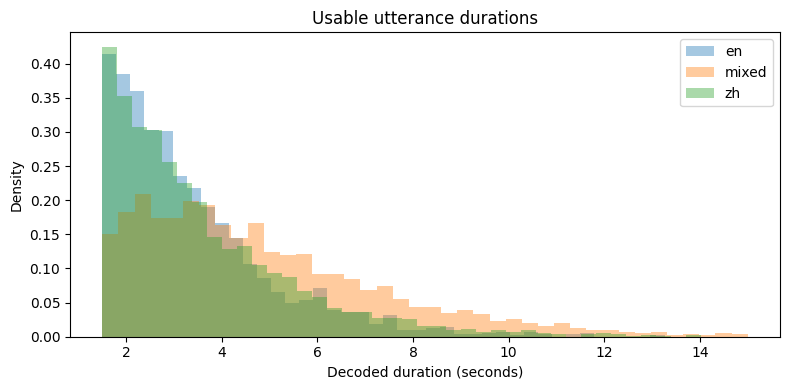

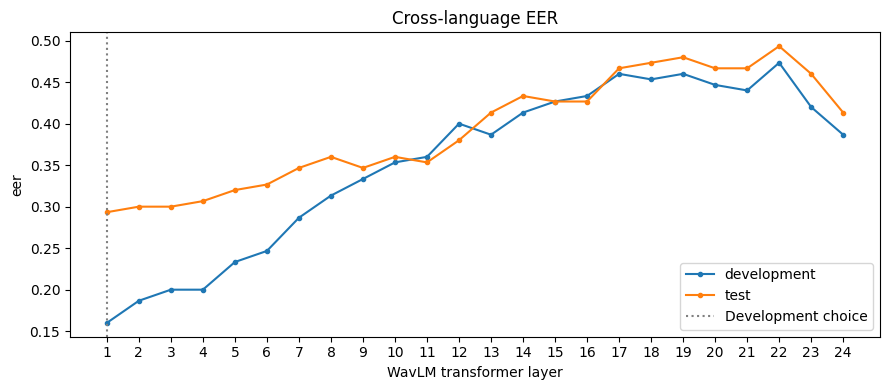

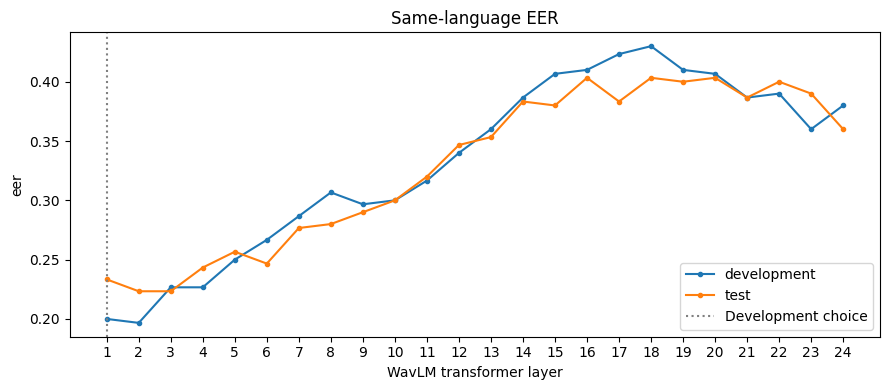

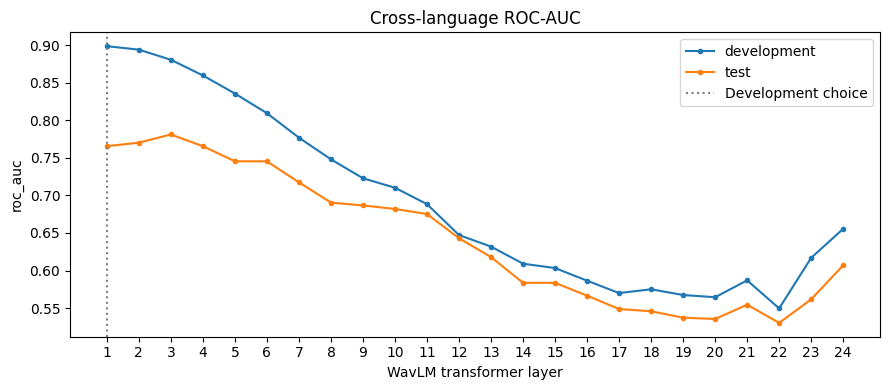

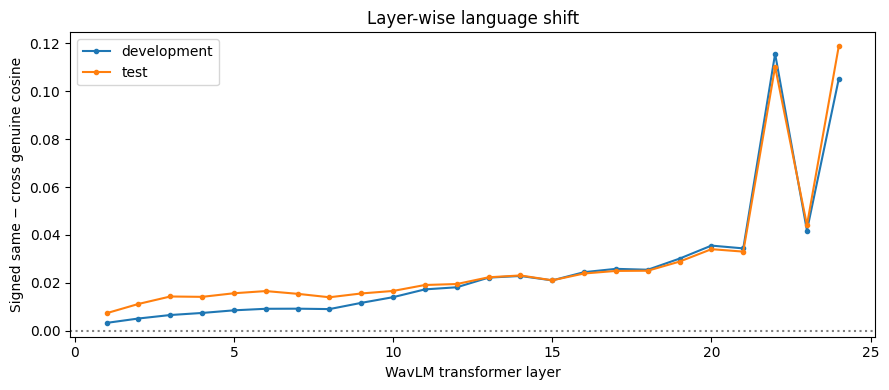

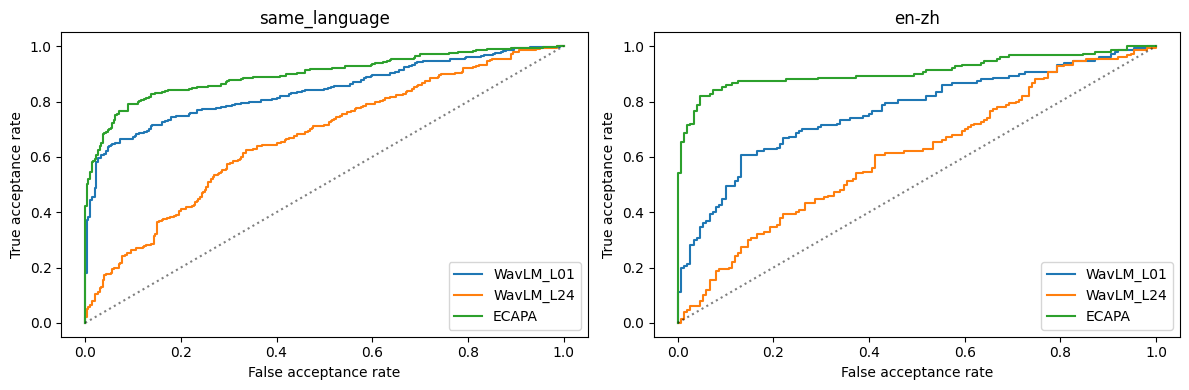

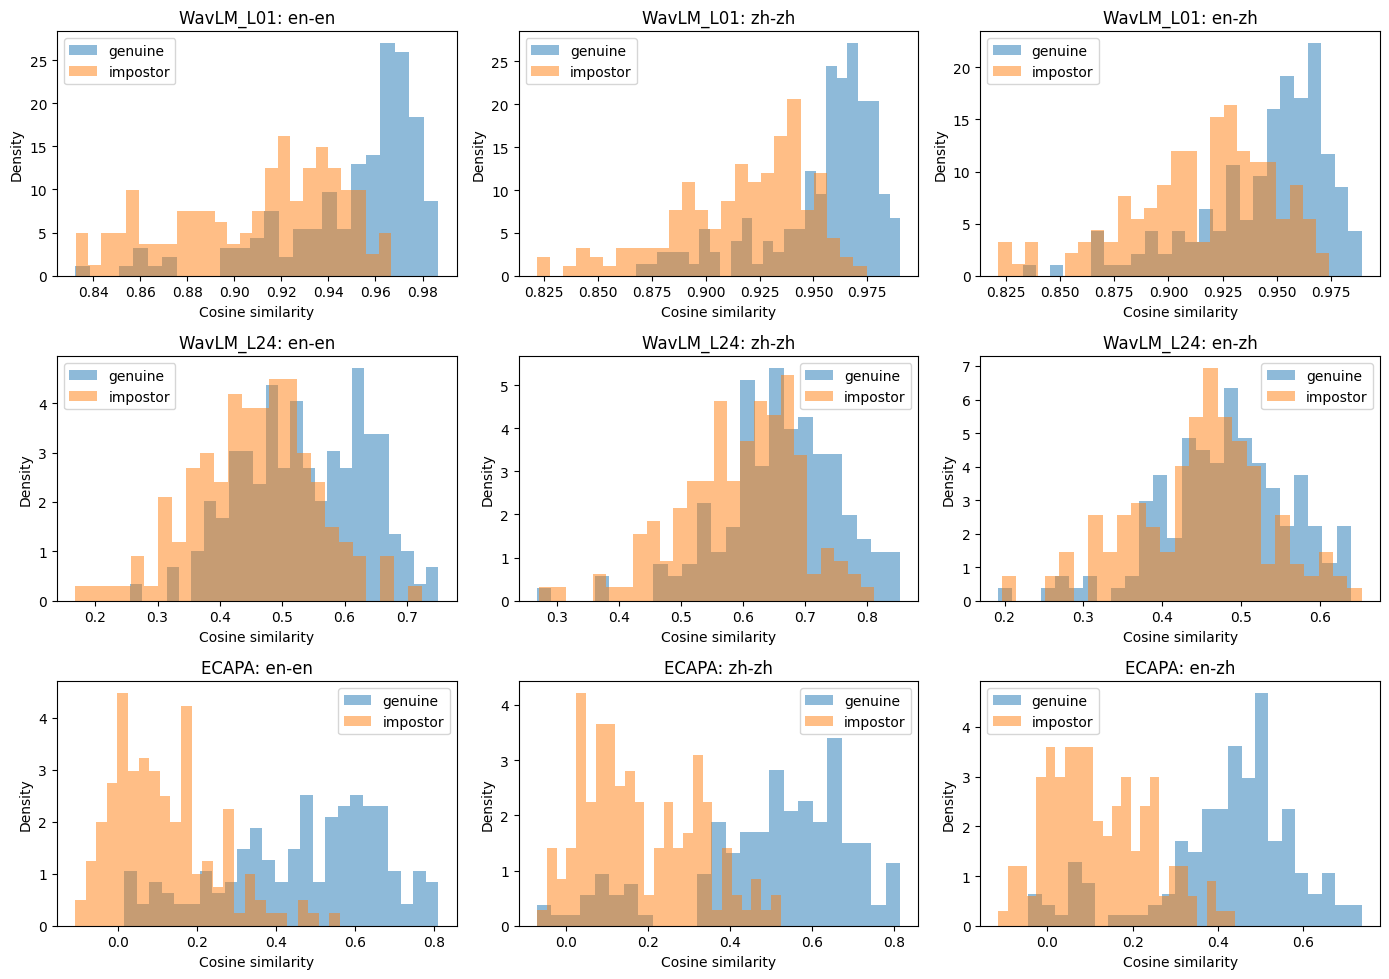

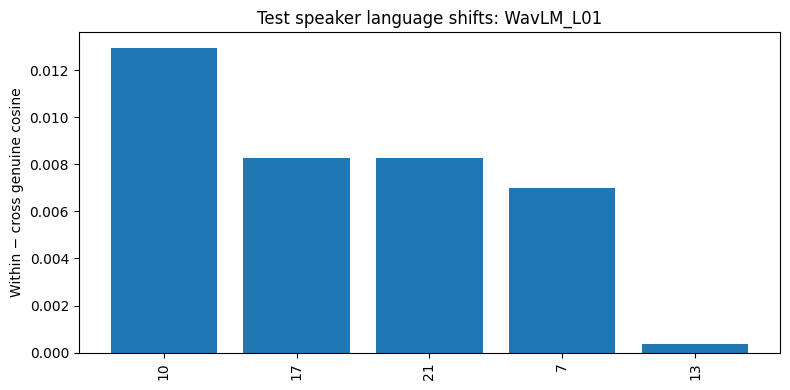

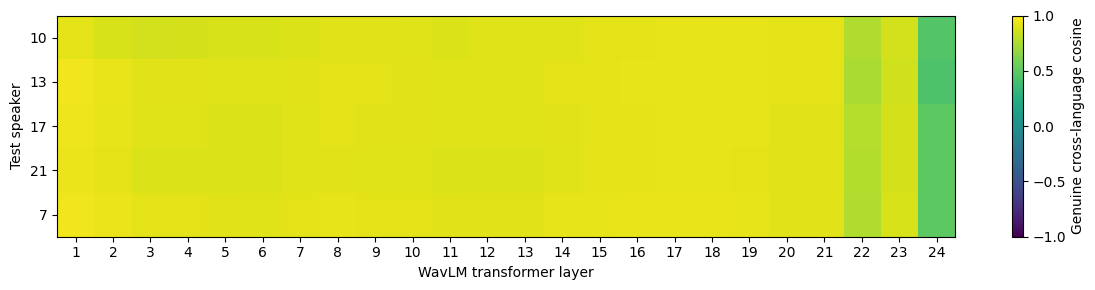

In [34]:
FIGURES=[]
def savefig(name):
    plt.tight_layout(); path=OUT/'figures'/f'{name}.png'
    plt.savefig(path,dpi=160,bbox_inches='tight'); plt.show(); plt.close(); FIGURES.append(name)
if len(usable):
    plt.figure(figsize=(8,4))
    for lang,g in usable.groupby('language'):
        plt.hist(g.duration,bins=40,alpha=.4,label=lang,density=True)
    plt.xlabel('Decoded duration (seconds)'); plt.ylabel('Density'); plt.legend()
    plt.title('Usable utterance durations'); savefig('duration_distributions')
if len(metrics):
    for condition,metric,title,name in [
        ('en-zh','eer','Cross-language EER','layer_cross_eer'),
        ('same_language','eer','Same-language EER','layer_same_eer'),
        ('en-zh','roc_auc','Cross-language ROC-AUC','layer_auc')]:
        plt.figure(figsize=(9,4))
        for part in ['development','test']:
            t=metrics[(metrics.partition==part)&(metrics.condition==condition)&metrics.model.str.startswith('WavLM')].copy()
            t['layer']=t.model.str[-2:].astype(int); t=t.sort_values('layer')
            plt.plot(t.layer,t[metric],marker='.',label=part)
        plt.axvline(int(BEST[-2:]),color='gray',ls=':',label='Development choice')
        plt.xticks(range(1,25)); plt.xlabel('WavLM transformer layer'); plt.ylabel(metric)
        plt.title(title); plt.legend(); savefig(name)
    plt.figure(figsize=(9,4))
    for part in ['development','test']:
        t=shift_table[(shift_table.partition==part)&shift_table.model.str.startswith('WavLM')].copy()
        t['layer']=t.model.str[-2:].astype(int); t=t.sort_values('layer')
        plt.plot(t.layer,t.language_shift,marker='.',label=part)
    plt.axhline(0,color='gray',ls=':'); plt.xlabel('WavLM transformer layer')
    plt.ylabel('Signed same − cross genuine cosine'); plt.title('Layer-wise language shift')
    plt.legend(); savefig('layer_language_shift')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,condition in zip(axes,['same_language','en-zh']):
        for name in SELECTED:
            block=scores[(scores.partition=='test')&(scores.model==name)]
            g=dict(condition_groups(block))[condition]
            fpr,tpr,_=roc_curve(g.label,g.score)
            ax.plot(fpr,tpr,label=name)
        ax.plot([0,1],[0,1],'k:',alpha=.5); ax.set(xlabel='False acceptance rate',ylabel='True acceptance rate',title=condition)
        ax.legend()
    savefig('heldout_roc')
    fig,axes=plt.subplots(len(SELECTED),3,figsize=(14,3.3*len(SELECTED)),squeeze=False)
    for i,name in enumerate(SELECTED):
        for j,condition in enumerate(['en-en','zh-zh','en-zh']):
            g=scores[(scores.partition=='test')&(scores.model==name)&(scores.condition==condition)]
            for label,title in [(1,'genuine'),(0,'impostor')]:
                axes[i,j].hist(g.loc[g.label.eq(label),'score'],bins=25,density=True,alpha=.5,label=title)
            axes[i,j].set(title=f'{name}: {condition}',xlabel='Cosine similarity',ylabel='Density'); axes[i,j].legend()
    savefig('similarity_overlap')
if len(speaker_analysis):
    t=speaker_analysis[(speaker_analysis.partition=='test')&(speaker_analysis.model==BEST)].sort_values('language_shift',ascending=False)
    plt.figure(figsize=(max(8,len(t)*.35),4)); plt.bar(t.speaker,t.language_shift)
    plt.xticks(rotation=90); plt.ylabel('Within − cross genuine cosine'); plt.title(f'Test speaker language shifts: {BEST}')
    savefig('speaker_shifts')
    h=speaker_analysis[(speaker_analysis.partition=='test')&speaker_analysis.model.str.startswith('WavLM')]
    h=h.pivot(index='speaker',columns='model',values='genuine_cross').sort_index(axis=1)
    plt.figure(figsize=(12,max(3,len(h)*.28)))
    plt.imshow(h.to_numpy(),aspect='auto',vmin=-1,vmax=1,cmap='viridis')
    plt.xticks(range(24),range(1,25)); plt.yticks(range(len(h)),h.index)
    plt.xlabel('WavLM transformer layer'); plt.ylabel('Test speaker'); plt.colorbar(label='Genuine cross-language cosine')
    savefig('speaker_layer_heatmap')


In [35]:
def table(frame,columns=None):
    if frame is None or frame.empty: return '_Unavailable: insufficient eligible data or trials._'
    x=frame[columns] if columns else frame
    def fmt(value):
        if pd.isna(value): return 'NA'
        text=f'{value:.4f}' if isinstance(value,(float,np.floating)) else str(value)
        return text.replace('|','&#124;').replace(chr(10),' ')
    lines=['| '+' | '.join(map(str,x.columns))+' |',
           '| '+' | '.join(['---']*len(x.columns))+' |']
    lines.extend('| '+' | '.join(fmt(v) for v in row)+' |' for row in x.itertuples(index=False,name=None))
    return chr(10).join(lines)
lang_overview=audit.groupby(['language','status']).agg(utterances=('uid','size'),
    decoded_seconds=('duration','sum')).reset_index()
test_shifts=shift_table[(shift_table.partition=='test')&shift_table.model.isin(SELECTED)] if len(shift_table) else pd.DataFrame()
top_speakers=(speaker_analysis[(speaker_analysis.partition=='test')&(speaker_analysis.model==BEST)]
    .sort_values('language_shift',ascending=False).head(10)) if len(speaker_analysis) else pd.DataFrame()
report=[
    '# Experiment 3 — Language-Invariant Speaker Representations',
    '**SMOKE TEST — diagnostic output only; not research results.**' if CFG['smoke_test'] else '**Full evaluation run.**',
    '## 1. Research question and hypotheses',
    'Do frozen ECAPA and WavLM layers retain speaker identity when the same speaker uses English versus Chinese? '
    'We hypothesized a positive within-minus-cross language shift, layer-dependent invariance and an ECAPA verification advantage. These are hypotheses, not assumed outcomes.',
    '## 2. Dataset overview and feasibility',
    f'Original metadata: {len(meta)} rows, {meta.loc[meta.speaker.ne(""),"speaker"].nunique()} speakers. '
    f'Decoded usable scope: {len(usable)} utterances. Eligible bilingual speakers: {len(eligible)}. '
    f'Speaker-disjoint evaluation computationally feasible: {FEASIBLE}. '
    'The four-speaker floor does not establish adequate statistical power. See dataset_audit.csv for every original row.',
    table(lang_overview), '\n'.join(f'- {n}' for n in dict.fromkeys(NOTES)),
    '## 3. Preprocessing and evaluation protocol',
    f'Audio was decoded from embedded bytes, converted to mono and resampled to {CFG["sample_rate"]} Hz. '
    f'Minimum duration {CFG["min_duration"]} s; RMS floor {CFG["silence_rms"]}. '
    'DC removal and attenuation-only peak limiting were language independent. No denoising or VAD. '
    'Byte-identical duplicates were excluded; contradictory duplicate annotations were excluded. '
    'Speaker partitions were freshly seeded, independent of official split labels. '
    f'Partition speaker counts: {dict(Counter(partition_map.values()))}. '
    'The train reserve was not used. Model and environment revisions are recorded in model_versions.json and environment.json.',
    '## 4. Models and embedding extraction',
    'ECAPA-TDNN used its pretrained speaker embedding encoder, frozen in evaluation mode. '
    'WavLM Large provided time-mean states for transformer layers 1–24, excluding initial state 0. '
    'These states are not a pretrained speaker-verification head. Padding was excluded with input and feature-frame masks. '
    f'Audio was chunked at {CFG["chunk_seconds"]} s (short tails merged); chunk states were frame-weighted for WavLM and duration-weighted for ECAPA. '
    'Both representations were L2 normalized before cosine scoring. No gradients or model adaptation were used.',
    '## 5. Verification trials and confounds',
    f'Saved {len(pairs)} primary and {len(mixed_pairs)} exploratory unique trials. '
    'Primary trials used only pure en/zh labels. Genuine and impostor counts were balanced per condition; '
    'equal per-speaker genuine and impostor-anchor quotas and bounded utterance pools limited dominance. '
    'Utterance sharing and speaker dyads still induce dependence. Balanced trial prevalence does not represent deployment prevalence.',
    table(confound_table),
    '## 6. Quantitative held-out results',
    'EER and ROC-AUC summarize the held-out score distribution. Fixed-threshold FRR and realized FAR use thresholds learned on development impostors. '
    'The 1% and 5% labels are nominal development FAR targets, not guarantees about test FAR. All rates are fractions, not percentages.',
    table(comparison),
    '### Speaker bootstrap intervals', table(bootstrap),
    'Intervals use speaker-node multiplicities for genuine trials and endpoint-product multiplicities for impostors. '
    'They condition on selected trials and the development-selected layer; no pair-independent bootstrap or significance claim is used.',
    '### Duration-matched sensitivity',
    f'{len(matched_pairs)} trials survived common mean-duration/absolute-gap strata across all six condition/class groups. '
    'This changes the evaluated sample, may reduce speaker balance and does not remove session or phonetic confounds.',
    table(matched_metrics[(matched_metrics.partition=='test')&matched_metrics.model.isin(SELECTED)]) if len(matched_metrics) else '_No feasible matched comparison._',
    '## 7. WavLM layers versus ECAPA',
    f'Development cross-language EER selected **{BEST}** (lowest layer wins a tie).' if BEST else 'No layer could be selected.',
    table(test_shifts),
    'Absolute EER degradation is cross minus pooled same-language EER; relative degradation divides by same-language EER and is undefined when that denominator is zero. '
    'The full 24-layer table is layer_metrics.csv. Test layer curves are supporting descriptions and do not select the layer.',
    '## 8. Per-speaker analysis', table(top_speakers),
    'Rankings show the largest signed within-minus-cross cosine reductions for the development-selected representation on test speakers. '
    'Counts, duration differences and session composition are in speaker_analysis.csv. Language shift is descriptive and is not necessarily caused by language itself.',
    '## 9. Code-switching exploratory analysis',
    table(mixed_metrics[(mixed_metrics.partition=='test')&mixed_metrics.model.isin(SELECTED)]) if len(mixed_metrics) else '_Insufficient mixed utterances or eligible speakers._',
    'Mixed labels were excluded from primary trials. en–mixed, zh–mixed and mixed–mixed use existing speaker partitions and may use different speaker subsets. '
    'These comparisons concern utterance-level code-switching, not speaker-change boundaries.',
    '## 10. Limitations',
    'Small speaker counts, correlated trials, finite impostor resolution, potential session/channel/duration/phonetic confounding, '
    'possible language-label noise, and domain mismatch from pretrained data limit conclusions. Mean pooling and chunking may lose useful temporal or contextual cues. '
    'Near-duplicates, re-encoded audio and overlapping excerpts are not removed by byte hashing. '
    'No VAD-based speech-frame selection was performed; unpadded audio can include internal silence. '
    'Bootstrap intervals are conditional, not selection-adjusted; no formal significance tests were performed. '
    'Model pretraining overlap with benchmark identities cannot be ruled out here. '    'GPU/library differences and mixed precision may cause small numeric variation.',
    '## 11. Conclusions',
]
if len(comparison) and not CFG['smoke_test']:
    cross=comparison[comparison.condition.eq('en-zh')].sort_values('eer')
    report.append('Measured held-out cross-language EERs: '+ '; '.join(f'{r.model}: {r.eer:.4f}' for r in cross.itertuples())+'. '
        'This is a descriptive sample comparison; uncertainty and confounds above apply.')
    if len(test_shifts): report.append('Measured genuine same-minus-cross cosine shifts: '+
        '; '.join(f'{r.model}: {r.language_shift:.4f}' for r in test_shifts.itertuples())+'.')
else:
    report.append('No research conclusion is drawn: this is a smoke run or the dataset failed the feasibility check.')
report += [
    '## 12. Relevance to speaker-change detection',
    'Language-dependent embedding changes could confound speaker-change systems. Verification invariance is a prerequisite worth studying, '
    'but this experiment does not evaluate boundary detection, segmentation, diarization error or temporal localization.',
    '### Relationship to Experiments 1 and 2',
    '| Experiment | Research question | Quantitative evidence |\n|---|---|---|\n'
    '| 1 | **Placeholder: research question not supplied.** | **Unavailable; do not infer results.** |\n'
    '| 2 | **Placeholder: research question not supplied.** | **Unavailable; do not infer results.** |\n'
    '| 3 | Does speaker identity survive a switch between English and Chinese in frozen representations? | Measured tables above, when feasible. |',
    'Experiments 1 and 2 require their original protocols/results before a factual research-question comparison can be completed.',
    '## 13. Follow-up experiments',
    'Collect more bilingual identities and balanced cross-session recordings; compare phonetic/duration-matched utterances, '
    'repeat with independent speaker partitions, assess near-duplicate audio, explore pretrained speaker pooling for WavLM, '
    'and evaluate actual speaker-change boundaries on separately annotated continuous recordings.',
    '## Figures',
]
for name in FIGURES: report.append(f'### {name.replace("_"," ")}\n![{name}](figures/{name}.png)')
report += ['## Reproduction metadata', '```json\n'+json.dumps(dict(config=CFG,models=MODEL_INFO,source_sha256=SOURCE_HASHES),indent=2)+'\n```']
(OUT/'experiment3_report.md').write_text('\n\n'.join(report))
atomic_json(OUT/'experiment_config.json',dict(**CFG,resolved_models=MODEL_INFO,
    source_sha256=SOURCE_HASHES,cache_keys=CACHE_KEYS,environment=PACKAGES))
atomic_json(OUT/'run_summary.json',dict(feasible=FEASIBLE,smoke=CFG['smoke_test'],selected_layer=BEST,
    primary_trials=len(pairs),mixed_trials=len(mixed_pairs),notes=NOTES,figures=FIGURES))
print('Saved report and artifacts to',OUT)
display(Markdown((OUT/'experiment3_report.md').read_text()))


Saved report and artifacts to /content/drive/MyDrive/ASCEND/experiment3_results


# Experiment 3 — Language-Invariant Speaker Representations

**Full evaluation run.**

## 1. Research question and hypotheses

Do frozen ECAPA and WavLM layers retain speaker identity when the same speaker uses English versus Chinese? We hypothesized a positive within-minus-cross language shift, layer-dependent invariance and an ECAPA verification advantage. These are hypotheses, not assumed outcomes.

## 2. Dataset overview and feasibility

Original metadata: 12314 rows, 23 speakers. Decoded usable scope: 8753 utterances. Eligible bilingual speakers: 23. Speaker-disjoint evaluation computationally feasible: True. The four-speaker floor does not establish adequate statistical power. See dataset_audit.csv for every original row.

| language | status | utterances | decoded_seconds |
| --- | --- | --- | --- |
| en | audio_rejected | 995 | 0.0000 |
| en | usable | 1855 | 6274.6553 |
| mixed | audio_rejected | 182 | 0.0000 |
| mixed | usable | 3143 | 15294.9424 |
| zh | audio_rejected | 2384 | 0.0000 |
| zh | usable | 3755 | 13449.3308 |



## 3. Preprocessing and evaluation protocol

Audio was decoded from embedded bytes, converted to mono and resampled to 16000 Hz. Minimum duration 1.5 s; RMS floor 1e-05. DC removal and attenuation-only peak limiting were language independent. No denoising or VAD. Byte-identical duplicates were excluded; contradictory duplicate annotations were excluded. Speaker partitions were freshly seeded, independent of official split labels. Partition speaker counts: {'train': 13, 'development': 5, 'test': 5}. The train reserve was not used. Model and environment revisions are recorded in model_versions.json and environment.json.

## 4. Models and embedding extraction

ECAPA-TDNN used its pretrained speaker embedding encoder, frozen in evaluation mode. WavLM Large provided time-mean states for transformer layers 1–24, excluding initial state 0. These states are not a pretrained speaker-verification head. Padding was excluded with input and feature-frame masks. Audio was chunked at 12.0 s (short tails merged); chunk states were frame-weighted for WavLM and duration-weighted for ECAPA. Both representations were L2 normalized before cosine scoring. No gradients or model adaptation were used.

## 5. Verification trials and confounds

Saved 1800 primary and 1800 exploratory unique trials. Primary trials used only pure en/zh labels. Genuine and impostor counts were balanced per condition; equal per-speaker genuine and impostor-anchor quotas and bounded utterance pools limited dominance. Utterance sharing and speaker dyads still induce dependence. Balanced trial prevalence does not represent deployment prevalence.

| partition | condition | label | n | mean_duration | mean_absolute_duration_gap | known_session_pairs | same_session_fraction | scope |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| development | en-en | 0 | 150 | 3.7556 | 2.2948 | 150 | 0.2067 | primary |
| development | en-en | 1 | 150 | 3.7207 | 2.1603 | 150 | 0.3933 | primary |
| development | en-zh | 0 | 150 | 3.7497 | 2.3053 | 150 | 0.2333 | primary |
| development | en-zh | 1 | 150 | 3.7595 | 2.3082 | 150 | 0.2733 | primary |
| development | zh-zh | 0 | 150 | 3.8386 | 2.2333 | 150 | 0.1667 | primary |
| development | zh-zh | 1 | 150 | 3.8202 | 2.0787 | 150 | 0.3333 | primary |
| test | en-en | 0 | 150 | 3.4273 | 1.9045 | 150 | 0.2400 | primary |
| test | en-en | 1 | 150 | 3.4611 | 1.8677 | 150 | 0.3467 | primary |
| test | en-zh | 0 | 150 | 3.4919 | 1.9972 | 150 | 0.2933 | primary |
| test | en-zh | 1 | 150 | 3.5076 | 2.0691 | 150 | 0.2533 | primary |
| test | zh-zh | 0 | 150 | 3.5163 | 2.0718 | 150 | 0.2067 | primary |
| test | zh-zh | 1 | 150 | 3.5541 | 1.9148 | 150 | 0.3600 | primary |
| development | en-mixed | 0 | 150 | 4.3632 | 2.8044 | 150 | 0.2267 | mixed |
| development | en-mixed | 1 | 150 | 4.4284 | 2.7863 | 150 | 0.2467 | mixed |
| development | mixed-mixed | 0 | 150 | 5.1862 | 3.3176 | 150 | 0.2067 | mixed |
| development | mixed-mixed | 1 | 150 | 5.1473 | 3.1946 | 150 | 0.3467 | mixed |
| development | zh-mixed | 0 | 150 | 4.4812 | 2.8615 | 150 | 0.2333 | mixed |
| development | zh-mixed | 1 | 150 | 4.4838 | 2.8187 | 150 | 0.1933 | mixed |
| test | en-mixed | 0 | 150 | 3.9718 | 2.4031 | 150 | 0.2867 | mixed |
| test | en-mixed | 1 | 150 | 4.0505 | 2.4354 | 150 | 0.2867 | mixed |
| test | mixed-mixed | 0 | 150 | 4.6502 | 2.6833 | 150 | 0.2267 | mixed |
| test | mixed-mixed | 1 | 150 | 4.6665 | 2.6366 | 150 | 0.3267 | mixed |
| test | zh-mixed | 0 | 150 | 4.1329 | 2.6195 | 150 | 0.2400 | mixed |
| test | zh-mixed | 1 | 150 | 4.1007 | 2.4854 | 150 | 0.3067 | mixed |

## 6. Quantitative held-out results

EER and ROC-AUC summarize the held-out score distribution. Fixed-threshold FRR and realized FAR use thresholds learned on development impostors. The 1% and 5% labels are nominal development FAR targets, not guarantees about test FAR. All rates are fractions, not percentages.

| partition | model | condition | n_genuine | n_impostor | n_speakers | eer | roc_auc | genuine_mean | genuine_std | genuine_median | impostor_mean | impostor_std | impostor_median | threshold_dev_1pct | dev_far_1pct | frr_fixed_1pct | far_fixed_1pct | dev_n_impostor | dev_far_resolution | threshold_dev_5pct | dev_far_5pct | frr_fixed_5pct | far_fixed_5pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| test | ECAPA | en-en | 150 | 150 | 5 | 0.1600 | 0.9160 | 0.4698 | 0.1984 | 0.4932 | 0.1151 | 0.1297 | 0.0979 | 0.4343 | 0.0133 | 0.3800 | 0.0267 | 150 | 0.0067 | 0.3475 | 0.0533 | 0.2933 | 0.0533 |
| test | ECAPA | en-zh | 150 | 150 | 5 | 0.1267 | 0.9094 | 0.4200 | 0.1672 | 0.4530 | 0.1201 | 0.1175 | 0.1027 | 0.5158 | 0.0133 | 0.7533 | 0.0000 | 150 | 0.0067 | 0.3445 | 0.0533 | 0.2333 | 0.0333 |
| test | ECAPA | zh-zh | 150 | 150 | 5 | 0.1533 | 0.8886 | 0.4974 | 0.2009 | 0.5326 | 0.1808 | 0.1370 | 0.1500 | 0.5110 | 0.0133 | 0.4467 | 0.0133 | 150 | 0.0067 | 0.4054 | 0.0533 | 0.2600 | 0.0600 |
| test | ECAPA | same_language | 300 | 300 | 5 | 0.1667 | 0.8979 | 0.4836 | 0.1998 | 0.5244 | 0.1480 | 0.1372 | 0.1192 | 0.4730 | 0.0133 | 0.4067 | 0.0200 | 300 | 0.0033 | 0.3811 | 0.0533 | 0.2567 | 0.0633 |
| test | WavLM_L01 | en-en | 150 | 150 | 5 | 0.2467 | 0.8337 | 0.9502 | 0.0309 | 0.9619 | 0.9092 | 0.0351 | 0.9180 | 0.9659 | 0.0133 | 0.6133 | 0.0067 | 150 | 0.0067 | 0.9582 | 0.0533 | 0.4267 | 0.0333 |
| test | WavLM_L01 | en-zh | 150 | 150 | 5 | 0.2933 | 0.7655 | 0.9446 | 0.0305 | 0.9537 | 0.9150 | 0.0333 | 0.9207 | 0.9708 | 0.0133 | 0.8467 | 0.0067 | 150 | 0.0067 | 0.9586 | 0.0533 | 0.6067 | 0.0733 |
| test | WavLM_L01 | zh-zh | 150 | 150 | 5 | 0.2200 | 0.8445 | 0.9538 | 0.0273 | 0.9623 | 0.9161 | 0.0316 | 0.9216 | 0.9717 | 0.0133 | 0.7467 | 0.0067 | 150 | 0.0067 | 0.9634 | 0.0533 | 0.5267 | 0.0200 |
| test | WavLM_L01 | same_language | 300 | 300 | 5 | 0.2333 | 0.8387 | 0.9520 | 0.0292 | 0.9619 | 0.9126 | 0.0335 | 0.9196 | 0.9713 | 0.0133 | 0.7467 | 0.0033 | 300 | 0.0033 | 0.9613 | 0.0533 | 0.4833 | 0.0233 |
| test | WavLM_L24 | en-en | 150 | 150 | 5 | 0.3533 | 0.7147 | 0.5363 | 0.0987 | 0.5317 | 0.4551 | 0.0976 | 0.4675 | 0.6668 | 0.0133 | 0.9267 | 0.0133 | 150 | 0.0067 | 0.5978 | 0.0533 | 0.6733 | 0.0533 |
| test | WavLM_L24 | en-zh | 150 | 150 | 5 | 0.4133 | 0.6070 | 0.4795 | 0.0829 | 0.4829 | 0.4469 | 0.0876 | 0.4557 | 0.6235 | 0.0133 | 0.9667 | 0.0133 | 150 | 0.0067 | 0.5788 | 0.0533 | 0.8800 | 0.0667 |
| test | WavLM_L24 | zh-zh | 150 | 150 | 5 | 0.3733 | 0.6945 | 0.6603 | 0.0972 | 0.6636 | 0.5941 | 0.0958 | 0.6067 | 0.7748 | 0.0133 | 0.8867 | 0.0133 | 150 | 0.0067 | 0.7397 | 0.0533 | 0.8067 | 0.0400 |
| test | WavLM_L24 | same_language | 300 | 300 | 5 | 0.3600 | 0.6687 | 0.5983 | 0.1158 | 0.6142 | 0.5246 | 0.1190 | 0.5274 | 0.7578 | 0.0133 | 0.9233 | 0.0133 | 300 | 0.0033 | 0.7223 | 0.0533 | 0.8600 | 0.0367 |

### Speaker bootstrap intervals

| partition | model | condition | metric | lower_95 | upper_95 | valid_bootstraps | speakers |
| --- | --- | --- | --- | --- | --- | --- | --- |
| test | ECAPA | en-en | eer | 0.0667 | 0.2467 | 199 | 5 |
| test | ECAPA | en-en | roc_auc | 0.8648 | 0.9788 | 199 | 5 |
| test | ECAPA | en-zh | eer | 0.0561 | 0.2067 | 200 | 5 |
| test | ECAPA | en-zh | roc_auc | 0.8714 | 0.9774 | 200 | 5 |
| test | ECAPA | zh-zh | eer | 0.0624 | 0.2467 | 200 | 5 |
| test | ECAPA | zh-zh | roc_auc | 0.8352 | 0.9696 | 200 | 5 |
| test | ECAPA | same_language | eer | 0.0767 | 0.2333 | 200 | 5 |
| test | ECAPA | same_language | roc_auc | 0.8569 | 0.9727 | 200 | 5 |
| test | WavLM_L01 | en-en | eer | 0.1733 | 0.3243 | 200 | 5 |
| test | WavLM_L01 | en-en | roc_auc | 0.7338 | 0.9100 | 200 | 5 |
| test | WavLM_L01 | en-zh | eer | 0.1933 | 0.4400 | 200 | 5 |
| test | WavLM_L01 | en-zh | roc_auc | 0.5905 | 0.8850 | 200 | 5 |
| test | WavLM_L01 | zh-zh | eer | 0.1465 | 0.2933 | 200 | 5 |
| test | WavLM_L01 | zh-zh | roc_auc | 0.7798 | 0.9174 | 200 | 5 |
| test | WavLM_L01 | same_language | eer | 0.1600 | 0.2968 | 200 | 5 |
| test | WavLM_L01 | same_language | roc_auc | 0.7583 | 0.9002 | 200 | 5 |
| test | WavLM_L24 | en-en | eer | 0.1533 | 0.4933 | 200 | 5 |
| test | WavLM_L24 | en-en | roc_auc | 0.5509 | 0.8951 | 200 | 5 |
| test | WavLM_L24 | en-zh | eer | 0.3400 | 0.4867 | 200 | 5 |
| test | WavLM_L24 | en-zh | roc_auc | 0.5233 | 0.7206 | 200 | 5 |
| test | WavLM_L24 | zh-zh | eer | 0.3065 | 0.4669 | 200 | 5 |
| test | WavLM_L24 | zh-zh | roc_auc | 0.6078 | 0.7771 | 200 | 5 |
| test | WavLM_L24 | same_language | eer | 0.3109 | 0.4083 | 200 | 5 |
| test | WavLM_L24 | same_language | roc_auc | 0.6049 | 0.7535 | 200 | 5 |

Intervals use speaker-node multiplicities for genuine trials and endpoint-product multiplicities for impostors. They condition on selected trials and the development-selected layer; no pair-independent bootstrap or significance claim is used.

### Duration-matched sensitivity

1260 trials survived common mean-duration/absolute-gap strata across all six condition/class groups. This changes the evaluated sample, may reduce speaker balance and does not remove session or phonetic confounds.

| partition | model | condition | n_genuine | n_impostor | n_speakers | eer | roc_auc | genuine_mean | genuine_std | genuine_median | impostor_mean | impostor_std | impostor_median | threshold_dev_1pct | dev_far_1pct | frr_fixed_1pct | far_fixed_1pct | dev_n_impostor | dev_far_resolution | threshold_dev_5pct | dev_far_5pct | frr_fixed_5pct | far_fixed_5pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| test | ECAPA | en-en | 107 | 107 | 5 | 0.1682 | 0.9168 | 0.4647 | 0.1927 | 0.4866 | 0.1196 | 0.1267 | 0.1010 | 0.4272 | 0.0194 | 0.3832 | 0.0187 | 103 | 0.0097 | 0.3481 | 0.0583 | 0.3084 | 0.0467 |
| test | ECAPA | en-zh | 107 | 107 | 5 | 0.1308 | 0.9132 | 0.4254 | 0.1675 | 0.4539 | 0.1231 | 0.1188 | 0.1054 | 0.5058 | 0.0194 | 0.6916 | 0.0000 | 103 | 0.0097 | 0.3349 | 0.0583 | 0.2150 | 0.0280 |
| test | ECAPA | zh-zh | 107 | 107 | 5 | 0.1308 | 0.9092 | 0.5012 | 0.1818 | 0.5304 | 0.1725 | 0.1332 | 0.1494 | 0.4598 | 0.0194 | 0.3178 | 0.0280 | 103 | 0.0097 | 0.3969 | 0.0583 | 0.2150 | 0.0748 |
| test | ECAPA | same_language | 214 | 214 | 5 | 0.1542 | 0.9090 | 0.4829 | 0.1878 | 0.5244 | 0.1461 | 0.1323 | 0.1198 | 0.4598 | 0.0146 | 0.3738 | 0.0234 | 206 | 0.0049 | 0.3512 | 0.0534 | 0.2196 | 0.0654 |
| test | WavLM_L01 | en-en | 107 | 107 | 5 | 0.2243 | 0.8524 | 0.9508 | 0.0311 | 0.9612 | 0.9078 | 0.0336 | 0.9177 | 0.9659 | 0.0194 | 0.6075 | 0.0000 | 103 | 0.0097 | 0.9612 | 0.0583 | 0.4953 | 0.0093 |
| test | WavLM_L01 | en-zh | 107 | 107 | 5 | 0.3084 | 0.7568 | 0.9450 | 0.0299 | 0.9544 | 0.9156 | 0.0341 | 0.9208 | 0.9637 | 0.0194 | 0.6636 | 0.0374 | 103 | 0.0097 | 0.9576 | 0.0583 | 0.5607 | 0.1121 |
| test | WavLM_L01 | zh-zh | 107 | 107 | 5 | 0.2056 | 0.8697 | 0.9546 | 0.0248 | 0.9627 | 0.9136 | 0.0330 | 0.9209 | 0.9713 | 0.0194 | 0.7477 | 0.0000 | 103 | 0.0097 | 0.9621 | 0.0583 | 0.4953 | 0.0187 |
| test | WavLM_L01 | same_language | 214 | 214 | 5 | 0.2103 | 0.8603 | 0.9527 | 0.0281 | 0.9618 | 0.9107 | 0.0333 | 0.9188 | 0.9713 | 0.0146 | 0.7523 | 0.0000 | 206 | 0.0049 | 0.9621 | 0.0534 | 0.5047 | 0.0140 |
| test | WavLM_L24 | en-en | 107 | 107 | 5 | 0.3738 | 0.7037 | 0.5295 | 0.1009 | 0.5373 | 0.4514 | 0.0976 | 0.4663 | 0.6668 | 0.0194 | 0.9439 | 0.0093 | 103 | 0.0097 | 0.6118 | 0.0583 | 0.7196 | 0.0280 |
| test | WavLM_L24 | en-zh | 107 | 107 | 5 | 0.4486 | 0.5678 | 0.4761 | 0.0860 | 0.4789 | 0.4532 | 0.0884 | 0.4574 | 0.6235 | 0.0194 | 0.9626 | 0.0093 | 103 | 0.0097 | 0.5887 | 0.0583 | 0.8972 | 0.0561 |
| test | WavLM_L24 | zh-zh | 107 | 107 | 5 | 0.3738 | 0.7041 | 0.6587 | 0.0890 | 0.6620 | 0.5932 | 0.0887 | 0.6001 | 0.7578 | 0.0194 | 0.8692 | 0.0187 | 103 | 0.0097 | 0.7322 | 0.0583 | 0.7944 | 0.0467 |
| test | WavLM_L24 | same_language | 214 | 214 | 5 | 0.3551 | 0.6694 | 0.5941 | 0.1149 | 0.6151 | 0.5223 | 0.1171 | 0.5241 | 0.7525 | 0.0146 | 0.9346 | 0.0093 | 206 | 0.0049 | 0.7168 | 0.0534 | 0.8738 | 0.0280 |

## 7. WavLM layers versus ECAPA

Development cross-language EER selected **WavLM_L01** (lowest layer wins a tie).

| partition | model | language_shift | eer_same | eer_cross | eer_degradation_absolute | eer_degradation_relative |
| --- | --- | --- | --- | --- | --- | --- |
| test | ECAPA | 0.0636 | 0.1667 | 0.1267 | -0.0400 | -0.2400 |
| test | WavLM_L01 | 0.0074 | 0.2333 | 0.2933 | 0.0600 | 0.2571 |
| test | WavLM_L24 | 0.1188 | 0.3600 | 0.4133 | 0.0533 | 0.1481 |

Absolute EER degradation is cross minus pooled same-language EER; relative degradation divides by same-language EER and is undefined when that denominator is zero. The full 24-layer table is layer_metrics.csv. Test layer curves are supporting descriptions and do not select the layer.

## 8. Per-speaker analysis

| partition | model | speaker | n_en | n_zh | n_mixed | genuine_en | genuine_zh | genuine_cross | language_shift | shift_magnitude | mean_duration_en | mean_duration_zh | duration_difference | session_composition |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| test | WavLM_L01 | 10 | 30 | 30 | 30 | 0.9349 | 0.9291 | 0.9190 | 0.0130 | 0.0130 | 2.8830 | 3.3060 | -0.4230 | {"en": {"2": 13, "4": 8, "3": 5, "1": 4}, "zh": {"2": 11, "4": 10, "3": 6, "1": 3}, "mixed": {"2": 13, "4": 8, "3": 8, "1": 1}} |
| test | WavLM_L01 | 17 | 30 | 30 | 30 | 0.9574 | 0.9552 | 0.9480 | 0.0083 | 0.0083 | 3.8516 | 2.9741 | 0.8775 | {"en": {"2": 13, "1": 7, "4": 5, "3": 5}, "zh": {"3": 13, "4": 7, "2": 5, "1": 5}, "mixed": {"4": 13, "3": 12, "1": 3, "2": 2}} |
| test | WavLM_L01 | 21 | 30 | 30 | 30 | 0.9394 | 0.9653 | 0.9441 | 0.0083 | 0.0083 | 3.2813 | 3.9184 | -0.6371 | {"en": {"2": 11, "1": 8, "3": 7, "4": 4}, "zh": {"1": 11, "3": 7, "2": 7, "4": 5}, "mixed": {"2": 14, "4": 7, "3": 5, "1": 4}} |
| test | WavLM_L01 | 7 | 30 | 30 | 27 | 0.9647 | 0.9651 | 0.9579 | 0.0070 | 0.0070 | 4.2197 | 4.5787 | -0.3590 | {"en": {"1": 16, "3": 13, "2": 1}, "zh": {"1": 17, "2": 7, "3": 6}, "mixed": {"1": 13, "2": 7, "3": 7}} |
| test | WavLM_L01 | 13 | 30 | 30 | 30 | 0.9545 | 0.9540 | 0.9539 | 0.0004 | 0.0004 | 3.0701 | 2.9933 | 0.0767 | {"en": {"3": 10, "4": 8, "2": 7, "1": 5}, "zh": {"4": 13, "3": 11, "2": 6}, "mixed": {"3": 12, "4": 10, "1": 5, "2": 3}} |

Rankings show the largest signed within-minus-cross cosine reductions for the development-selected representation on test speakers. Counts, duration differences and session composition are in speaker_analysis.csv. Language shift is descriptive and is not necessarily caused by language itself.

## 9. Code-switching exploratory analysis

| partition | model | condition | n_genuine | n_impostor | n_speakers | eer | roc_auc | genuine_mean | genuine_std | genuine_median | impostor_mean | impostor_std | impostor_median | threshold_dev_1pct | dev_far_1pct | frr_fixed_1pct | far_fixed_1pct | dev_n_impostor | dev_far_resolution | threshold_dev_5pct | dev_far_5pct | frr_fixed_5pct | far_fixed_5pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| test | ECAPA | en-mixed | 150 | 150 | 5 | 0.1667 | 0.8925 | 0.4463 | 0.1976 | 0.4838 | 0.1209 | 0.1247 | 0.1128 | 0.4548 | 0.0133 | 0.4133 | 0.0067 | 150 | 0.0067 | 0.3224 | 0.0533 | 0.2000 | 0.0667 |
| test | ECAPA | mixed-mixed | 150 | 150 | 5 | 0.1267 | 0.9268 | 0.5609 | 0.1947 | 0.6245 | 0.1469 | 0.1424 | 0.1291 | 0.4556 | 0.0133 | 0.1600 | 0.0200 | 150 | 0.0067 | 0.3814 | 0.0533 | 0.1333 | 0.0600 |
| test | ECAPA | zh-mixed | 150 | 150 | 5 | 0.1667 | 0.8803 | 0.4974 | 0.2063 | 0.5627 | 0.1658 | 0.1458 | 0.1480 | 0.5206 | 0.0133 | 0.4267 | 0.0200 | 150 | 0.0067 | 0.4297 | 0.0533 | 0.2667 | 0.0533 |
| test | WavLM_L01 | en-mixed | 150 | 150 | 5 | 0.2467 | 0.7962 | 0.9479 | 0.0314 | 0.9586 | 0.9156 | 0.0319 | 0.9214 | 0.9715 | 0.0133 | 0.8000 | 0.0000 | 150 | 0.0067 | 0.9604 | 0.0533 | 0.5667 | 0.0533 |
| test | WavLM_L01 | mixed-mixed | 150 | 150 | 5 | 0.1933 | 0.8765 | 0.9616 | 0.0265 | 0.9700 | 0.9205 | 0.0309 | 0.9271 | 0.9737 | 0.0133 | 0.6000 | 0.0000 | 150 | 0.0067 | 0.9679 | 0.0533 | 0.4533 | 0.0067 |
| test | WavLM_L01 | zh-mixed | 150 | 150 | 5 | 0.2467 | 0.8091 | 0.9526 | 0.0309 | 0.9641 | 0.9173 | 0.0330 | 0.9212 | 0.9742 | 0.0133 | 0.7867 | 0.0067 | 150 | 0.0067 | 0.9647 | 0.0533 | 0.5000 | 0.0333 |
| test | WavLM_L24 | en-mixed | 150 | 150 | 5 | 0.3733 | 0.6646 | 0.5180 | 0.0944 | 0.5228 | 0.4622 | 0.0890 | 0.4678 | 0.6455 | 0.0133 | 0.9200 | 0.0133 | 150 | 0.0067 | 0.6199 | 0.0533 | 0.8467 | 0.0267 |
| test | WavLM_L24 | mixed-mixed | 150 | 150 | 5 | 0.3867 | 0.6710 | 0.6324 | 0.1080 | 0.6328 | 0.5625 | 0.1096 | 0.5671 | 0.7856 | 0.0133 | 0.9467 | 0.0000 | 150 | 0.0067 | 0.7204 | 0.0533 | 0.7467 | 0.0733 |
| test | WavLM_L24 | zh-mixed | 150 | 150 | 5 | 0.4267 | 0.6215 | 0.6235 | 0.1163 | 0.6333 | 0.5754 | 0.1080 | 0.5830 | 0.7494 | 0.0133 | 0.8400 | 0.0267 | 150 | 0.0067 | 0.7134 | 0.0533 | 0.7733 | 0.0800 |

Mixed labels were excluded from primary trials. en–mixed, zh–mixed and mixed–mixed use existing speaker partitions and may use different speaker subsets. These comparisons concern utterance-level code-switching, not speaker-change boundaries.

## 10. Limitations

Small speaker counts, correlated trials, finite impostor resolution, potential session/channel/duration/phonetic confounding, possible language-label noise, and domain mismatch from pretrained data limit conclusions. Mean pooling and chunking may lose useful temporal or contextual cues. Near-duplicates, re-encoded audio and overlapping excerpts are not removed by byte hashing. No VAD-based speech-frame selection was performed; unpadded audio can include internal silence. Bootstrap intervals are conditional, not selection-adjusted; no formal significance tests were performed. Model pretraining overlap with benchmark identities cannot be ruled out here. GPU/library differences and mixed precision may cause small numeric variation.

## 11. Conclusions

Measured held-out cross-language EERs: ECAPA: 0.1267; WavLM_L01: 0.2933; WavLM_L24: 0.4133. This is a descriptive sample comparison; uncertainty and confounds above apply.

Measured genuine same-minus-cross cosine shifts: ECAPA: 0.0636; WavLM_L01: 0.0074; WavLM_L24: 0.1188.

## 12. Relevance to speaker-change detection

Language-dependent embedding changes could confound speaker-change systems. Verification invariance is a prerequisite worth studying, but this experiment does not evaluate boundary detection, segmentation, diarization error or temporal localization.

### Relationship to Experiments 1 and 2

| Experiment | Research question | Quantitative evidence |
|---|---|---|
| 1 | **Placeholder: research question not supplied.** | **Unavailable; do not infer results.** |
| 2 | **Placeholder: research question not supplied.** | **Unavailable; do not infer results.** |
| 3 | Does speaker identity survive a switch between English and Chinese in frozen representations? | Measured tables above, when feasible. |

Experiments 1 and 2 require their original protocols/results before a factual research-question comparison can be completed.

## 13. Follow-up experiments

Collect more bilingual identities and balanced cross-session recordings; compare phonetic/duration-matched utterances, repeat with independent speaker partitions, assess near-duplicate audio, explore pretrained speaker pooling for WavLM, and evaluate actual speaker-change boundaries on separately annotated continuous recordings.

## Figures

### duration distributions
![duration_distributions](figures/duration_distributions.png)

### layer cross eer
![layer_cross_eer](figures/layer_cross_eer.png)

### layer same eer
![layer_same_eer](figures/layer_same_eer.png)

### layer auc
![layer_auc](figures/layer_auc.png)

### layer language shift
![layer_language_shift](figures/layer_language_shift.png)

### heldout roc
![heldout_roc](figures/heldout_roc.png)

### similarity overlap
![similarity_overlap](figures/similarity_overlap.png)

### speaker shifts
![speaker_shifts](figures/speaker_shifts.png)

### speaker layer heatmap
![speaker_layer_heatmap](figures/speaker_layer_heatmap.png)

## Reproduction metadata

```json
{
  "config": {
    "seed": 42,
    "smoke_test": false,
    "root": "/content/drive/MyDrive/ASCEND",
    "sample_rate": 16000,
    "min_duration": 1.5,
    "silence_rms": 1e-05,
    "chunk_seconds": 12.0,
    "batch_size": 2,
    "wavlm_amp": true,
    "min_per_language": 3,
    "utterances_per_speaker_language": 30,
    "pairs_per_speaker_condition": 30,
    "bootstrap_replicates": 200,
    "smoke_speakers": 8,
    "smoke_utterances_per_language": 4,
    "cache_processed_audio": true,
    "code_version": "experiment3-v1.0",
    "wavlm_model": "microsoft/wavlm-large",
    "ecapa_model": "speechbrain/spkrec-ecapa-voxceleb",
    "wavlm_revision": "main",
    "ecapa_revision": "main"
  },
  "models": {
    "ecapa": {
      "repo": "speechbrain/spkrec-ecapa-voxceleb",
      "revision": "main",
      "sha": "0f99f2d0ebe89ac095bcc5903c4dd8f72b367286"
    },
    "wavlm": {
      "repo": "microsoft/wavlm-large",
      "revision": "main",
      "sha": "c1423ed94bb01d80a3f5ce5bc39f6026a0f4828c"
    }
  },
  "source_sha256": {
    "train-00000-of-00003.parquet": "3d66ba76f324e0711b779cfb01ee4e772a24a929e1d77a2063cde0506f75976f",
    "train-00001-of-00003.parquet": "569f84f771c3637ca8535bd35e10e62feed2c240833534711909a9c04f51e589",
    "train-00002-of-00003.parquet": "aa76b7ef4a74ff111fd1d2573d0b69e6b6f901df6054618d8e5658a7a394523e",
    "validation-00000-of-00001.parquet": "3bdec53d2abfd3dd4f0d86a6df4e27e60f20660edc9b66055ae0ef8ec05cf7e2",
    "test-00000-of-00001.parquet": "a4c81d2b5ed6124f052089a695972808c16e0ce0c365ec9773c5d1a8fcf043a7"
  }
}
```

## Output checks

Check saved metrics, manifests, figures, and report artifacts.


In [36]:
required=['experiment3_report.md','dataset_audit.csv','verification_pairs.csv',
    'layer_metrics.csv','speaker_analysis.csv','experiment_config.json',
    'speaker_partitions.csv','metadata_index.parquet','run_summary.json']
assert all((OUT/f).exists() for f in required)
if FEASIBLE:
    assert len(pairs)>0 and BEST in SELECTED
    assert len(metrics[metrics.model.str.startswith('WavLM')].model.unique())==24
    dev_s=set(inference_rows.loc[inference_rows.partition.eq('development'),'speaker'])
    test_s=set(inference_rows.loc[inference_rows.partition.eq('test'),'speaker'])
    assert not dev_s & test_s
    for name,group in scores.groupby('model'):
        assert set(group.pair_id)==set(pairs.pair_id)
    assert not pairs[['language_a','language_b']].isin(['mixed']).any().any()
print('Artifact and protocol checks passed. Mode:', 'SMOKE' if CFG['smoke_test'] else 'FULL')
memory()


Artifact and protocol checks passed. Mode: FULL
RAM 4.02 GiB; GPU allocated 0.03 GiB; peak 1.78 GiB
